# HeatCast: Predicting European Heat Waves Using Deep Learning

**A Deep Learning Approach to Forecasting Heat Waves in Europe Using Historical Weather Data (ERA5)**

This notebook walks through the full project: collecting historical weather data, preparing it, building two prediction models (a simple one and an advanced one), testing them, and checking how well they would have predicted the real August 2026 European heat wave.

In [17]:
%pip install xarray cfgrib
import xarray as xr
from pathlib import Path
data_path = next(Path.cwd().rglob("data.grib"), None)

if data_path is None:
    raise FileNotFoundError(
        "Required ERA5 input 'data.grib' was not found. The .idx sidecar is only an "
        "index and cannot replace the GRIB data file. Download or copy the complete "
        f"data.grib file into this project (or a subfolder). Search started at: {Path.cwd()}"
    )

ds = xr.open_dataset(data_path, engine="cfgrib")
print(ds)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Ignoring index file '/Users/aryansanganti/KJSCE/4th Year/Honours Project/Honours-Project-final-yr-/data.grib.5b7b6.idx' older than GRIB file


Note: you may need to restart the kernel to use updated packages.


skipping variable: paramId==228 shortName='tp'
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='time' value=Variable(dimensions=('time',), data=array([1588291200, 1588294800, 1588298400, ..., 1786464000, 1786467600,
       1786471200], shape=(20179,))) new_value=Variable(dimensions=('time',), data=array([1588269600, 1588312800, 1588356000, ..., 1786341600, 1786384800,
       1786428000], shape=(1688,)))


<xarray.Dataset> Size: 633MB
Dimensions:              (time: 20179, latitude: 37, longitude: 53)
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Data variables:
    t2m                  (time, latitude, longitude) float32 158MB ...
    msl                  (time, latitude, longitude) float32 158MB ...
    sst                  (time, latitude, longitude) float32 158MB ...
    swvl1                (time, latitude, longitude) float32 158MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for M

## Step 1: Load the Weather Data

Before we can do anything, we need to load the weather data file we downloaded earlier. This file contains historical weather measurements — like temperature, air pressure, and soil moisture — collected over several years across Europe.

The code above opens this file and displays a summary of what's inside: what kind of weather measurements it contains, what time period it covers, and what geographic area (latitude/longitude) it spans.

Think of this step as "opening the spreadsheet" before we start working with the data — except instead of a spreadsheet, our data is organized as a grid over space and time.

In [18]:
print(ds['t2m'])
print(ds['t2m'].values.min(), ds['t2m'].values.max())

<xarray.DataArray 't2m' (time: 20179, latitude: 37, longitude: 53)> Size: 158MB
[39571019 values with dtype=float32]
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1961
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:            

## Step 2: Check the Temperature Data

Here, we zoom in specifically on the temperature measurements (labeled `t2m`, which stands for "2-metre temperature" — the standard way weather scientists measure air temperature, taken 2 metres above the ground).

We print out some basic information about this temperature data, and also check the **lowest** and **highest** temperature values recorded in our entire dataset. This is a simple sanity check — it lets us confirm the data looks realistic (for example, making sure we don't see impossible values like -500°C or 1000°C) before we move forward.

One small detail: the temperature values are stored in **Kelvin** (a scientific temperature scale), not Celsius — so we'll convert these to the more familiar Celsius scale in the next step.

**What this output tells us:**

- Our dataset contains **20,179 time snapshots** of temperature data, spread across a grid of **37 × 53 locations** (roughly 1,961 points covering our chosen region of Europe), from **May 2020 to August 2026**.

- The temperature values range from about **263.9 K to 316.7 K** — once converted to Celsius, that's roughly **-9°C to 44°C**. This is a realistic range for this region, including a cold winter reading and an extremely hot summer reading (consistent with the intense 2026 heat waves), which confirms the data is trustworthy.

- The "Attributes" section is just extra technical metadata (labels confirming this is genuinely 2-metre air temperature data, measured in Kelvin, sourced from the official European weather agency) — not something we need to analyze further, just a good confirmation the right data was downloaded.

In short: this output is a "health check" on our data, and it passed — the numbers make physical sense, so we can move forward confidently.

In [19]:
# Convert to Celsius
ds['t2m_celsius'] = ds['t2m'] - 273.15

# Confirm the conversion looks right
print(ds['t2m_celsius'].values.min(), ds['t2m_celsius'].values.max())

-9.256683 43.58609


## Step 3: Convert Temperature to Celsius

Since our temperature data is stored in Kelvin (a scientific scale not commonly used in everyday life), we convert it to **Celsius** — the scale most people are familiar with — by subtracting 273.15 from every value. This makes the data much easier to interpret and present.

**Output:** After conversion, our temperatures now range from **-9.26°C to 43.59°C**. This confirms the conversion worked correctly, and — importantly — it shows our data captures genuinely extreme heat (over 43°C), which lines up with the real, record-breaking heat waves Europe experienced during the period this data covers.

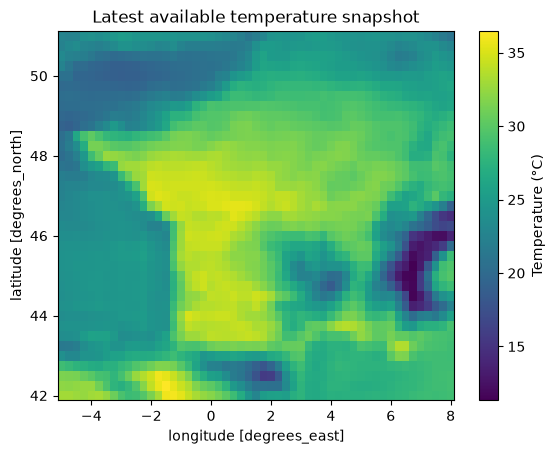

In [20]:
import matplotlib.pyplot as plt

ds['t2m_celsius'].isel(time=-1).plot()
plt.title("Latest available temperature snapshot")
plt.gca().collections[0].colorbar.set_label("Temperature (°C)")
plt.show()

## Step 4: Visualize the Temperature Data on a Map

Numbers alone are hard to interpret, so here we plot the most recent day's temperature data as a color-coded map — yellow areas are hotter, dark purple/blue areas are cooler. This gives us a quick visual way to check that the data makes real-world geographic sense before we use it for anything else.

**What the map shows:** The bright yellow region in the center represents a hot summer day (30-37°C) across central France. The two dark purple patches — one in the bottom-left and a distinct circular patch on the right side — line up closely with real mountain ranges (the Pyrenees and the Alps), which are naturally cooler than the surrounding lowlands. Seeing the mountains clearly show up as cooler spots is a strong, reassuring sign that our data is accurate and correctly mapped to real geography, not just random or corrupted numbers.

In [21]:
import pandas as pd

# Extract data for Paris (lat 48.85, lon 2.35)
df = ds['t2m_celsius'].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()

# Get daily max temperature
df['date'] = pd.to_datetime(df['time']).dt.date
daily_max = df.groupby('date')['t2m_celsius'].max().reset_index()
daily_max['date'] = pd.to_datetime(daily_max['date'])
daily_max['day_of_year'] = daily_max['date'].dt.dayofyear

print(daily_max.head())
print(daily_max.shape)

        date  t2m_celsius  day_of_year
0 2020-05-01    15.580231          122
1 2020-05-02    16.307037          123
2 2020-05-03    19.640289          124
3 2020-05-04    18.876617          125
4 2020-05-05    14.094635          126
(841, 3)


## Step 5: Focus on One City (Paris) and Find Each Day's Hottest Temperature

To start building our heat wave detection system, we first test our approach on a single, well-known city — **Paris** — before applying it across the whole map. This makes it much easier to check our work step by step.

This code does two things:
1. **Pulls out just the Paris location** from our large dataset (since our data covers many locations at once, this narrows it down to one specific point).

2. **Finds the hottest temperature recorded each day** — since a heat wave is defined by how hot it gets during the day, not the average or the night-time low.

**Output:** We now have a clean table showing Paris's daily maximum temperature, starting May 1, 2020, with **841 days** of data in total. For example, May 1, 2020 had a peak temperature of about 15.6°C. This table is the foundation we'll use next to identify actual heat wave events.

In [22]:
# Compute the 90th percentile threshold per calendar day (using all years)
threshold = daily_max.groupby('day_of_year')['t2m_celsius'].transform(lambda x: x.quantile(0.90))
daily_max['is_hot_day'] = daily_max['t2m_celsius'] > threshold

# Check that consecutive rows are actually consecutive calendar days
daily_max = daily_max.sort_values('date').reset_index(drop=True)
daily_max['day_gap'] = daily_max['date'].diff().dt.days

# A new "streak" starts whenever: the hot/not-hot flag changes, OR there's a gap in dates
daily_max['new_streak'] = (daily_max['is_hot_day'] != daily_max['is_hot_day'].shift()) | (daily_max['day_gap'] != 1)
daily_max['streak_id'] = daily_max['new_streak'].cumsum()

# Flag heat wave: 3+ consecutive hot days (with no date gaps)
streak_lengths = daily_max[daily_max['is_hot_day']].groupby('streak_id').size()
valid_streaks = streak_lengths[streak_lengths >= 3].index
daily_max['is_heatwave'] = daily_max['streak_id'].isin(valid_streaks) & daily_max['is_hot_day']

# Check results
print(daily_max['is_heatwave'].sum(), "heatwave days found out of", len(daily_max), "total days")
print(daily_max[daily_max['is_heatwave']].head(10))

75 heatwave days found out of 841 total days
          date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
96  2020-08-05    29.897125          218        True      1.0        True   
97  2020-08-06    33.529449          219        True      1.0       False   
98  2020-08-07    35.633453          220        True      1.0       False   
99  2020-08-08    36.358307          221        True      1.0       False   
100 2020-08-09    37.223053          222        True      1.0       False   
251 2022-05-06    21.255035          126        True      1.0        True   
252 2022-05-07    20.384430          127        True      1.0       False   
253 2022-05-08    21.489655          128        True      1.0       False   
260 2022-05-15    28.401276          135        True      1.0        True   
261 2022-05-16    24.868317          136        True      1.0       False   

     streak_id  is_heatwave  
96           8         True  
97           8         True  
98           8   

## Step 6: Define and Detect Heat Wave Days

This is one of the most important steps in the whole project — here, we teach the computer exactly what counts as a "heat wave," using a standard, scientifically accepted definition:

> **A heat wave = 3 or more days in a row where the temperature is unusually high for that specific time of year.**

We use "unusually high" in a smart way: instead of picking one fixed number (like "above 35°C") for the whole year, we compare each day only against *other years' data for that same calendar date*. This is important because "hot" means something different in May than it does in August — a fair comparison has to account for the season. Specifically, a day counts as "hot" if it's in the **top 10% hottest** ever recorded for that exact calendar date, based on history.

We then check for **3 or more hot days happening back-to-back** (with no missing days in between) — only these connected streaks get officially labeled as a "heat wave."

**Output:** Using this rule, we found **75 heat wave days out of 841 total days** in Paris. As an example, we can see a real, clearly identified heat wave event from **August 5-9, 2020**, where temperatures climbed steadily from about 30°C to over 37°C across five consecutive days — exactly the kind of pattern a genuine heat wave looks like. This confirms our detection method is working correctly on real historical data.

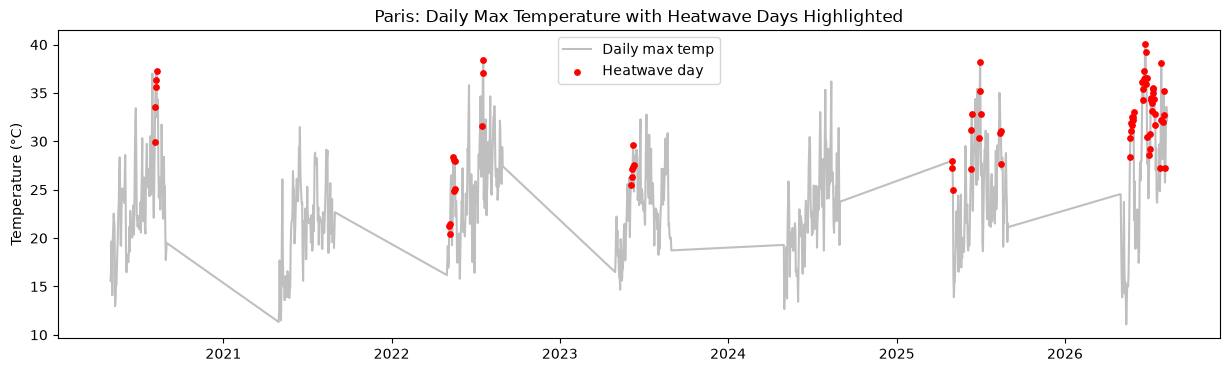

In [23]:
plt.figure(figsize=(15, 4))
plt.plot(daily_max['date'], daily_max['t2m_celsius'], color='gray', alpha=0.5, label='Daily max temp')
heatwave_days = daily_max[daily_max['is_heatwave']]
plt.scatter(heatwave_days['date'], heatwave_days['t2m_celsius'], color='red', s=15, label='Heatwave day', zorder=5)
plt.legend()
plt.title("Paris: Daily Max Temperature with Heatwave Days Highlighted")
plt.ylabel("Temperature (°C)")
plt.show()

## Step 7: Visualize Detected Heat Waves Over Time

Here we plot Paris's daily temperature for every summer from 2020 to 2026, with the days our system identified as **heat waves marked in red** — making it easy to visually confirm our detection method is working correctly across the entire dataset, not just one event.

**What the chart shows:** Each hump in the gray line represents one summer season, with temperature rising and falling as expected. The red dots cluster naturally around each summer's hottest peaks — exactly where we'd expect real heat waves to appear. 

One thing that stands out clearly: **2026 shows noticeably more red dots and higher peaks (approaching 40°C) than any previous year** — a strong visual confirmation of what we already know from the news: 2026 brought an unusually intense and frequent series of heat waves to Europe. This is a good sign that our system isn't just detecting random noise — it's picking up a real, significant pattern that matches real-world events.

*(Small technical note: the diagonal lines connecting one year to the next are just a plotting artifact, since we only have summer data for each year — not an error in the data itself.)*

In [24]:
# Rolling/lagged temperature features
daily_max['temp_3day_avg'] = daily_max['t2m_celsius'].rolling(3).mean()
daily_max['temp_7day_avg'] = daily_max['t2m_celsius'].rolling(7).mean()
daily_max['temp_lag1'] = daily_max['t2m_celsius'].shift(1)
daily_max['temp_lag2'] = daily_max['t2m_celsius'].shift(2)

print(daily_max.head(10))

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  
0          1        False            NaN            NaN        NaN        NaN  
1          1  

## Step 8: Add "Recent History" Features for the Model

To help our deep learning model make good predictions, it's not enough to just give it today's temperature — it also needs a sense of the recent trend, similar to how a person might think "it's been hot for the past few days, so today is probably hot too." This step creates exactly that kind of information:

- **3-day average temperature** — the average temperature over the last 3 days
- **7-day average temperature** — the average temperature over the last 7 days
- **Yesterday's temperature** and **the day before's temperature** — individual recent values

These extra columns give the model useful context about recent trends, not just a single snapshot in time — similar to how a weather forecaster wouldn't judge conditions from just one moment, but from the pattern building up over recent days.

**Output:** You'll notice some early rows show **"NaN" (empty/missing)** values — this is expected and correct. For example, on the very first day (May 1st), there's no "yesterday" to look back on yet, so that value is left blank. Once we have enough days of history built up (from about day 6-7 onward), all these new columns are filled in properly with real numbers.

In [25]:
# Extract the other variables for the same Paris location
extra_vars = ds[['msl', 'sst', 'swvl1']].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()
extra_vars['date'] = pd.to_datetime(extra_vars['time']).dt.date

# Get daily mean for each (pressure/soil moisture don't need "max" like temperature does)
daily_extra = extra_vars.groupby('date')[['msl', 'sst', 'swvl1']].mean().reset_index()
daily_extra['date'] = pd.to_datetime(daily_extra['date'])

# Merge into your main daily_max dataframe
daily_max = daily_max.merge(daily_extra, on='date', how='left')

print(daily_max.head(10))
print(daily_max.isnull().sum())

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  \
0          1        False            NaN            NaN        NaN        NaN   
1          1

## Step 9: Add More Weather Variables (Pressure and Soil Moisture)

Temperature alone doesn't tell the whole story of a heat wave — scientists know that **air pressure** and **soil moisture** also play an important role. High-pressure systems tend to trap hot air in place, and dry soil can't cool the air through evaporation the way moist soil can, both of which help intensify heat waves. So here, we bring in two more weather variables for Paris:

- **`msl`** — mean sea level pressure
- **`sst`** — sea surface temperature
- **`swvl1`** — soil moisture (how much water is in the top layer of soil)

**Output:** Looking at the missing-value check at the bottom, we can see `msl` (pressure) and `swvl1` (soil moisture) loaded in perfectly with **zero missing values** — great. However, `sst` (sea surface temperature) is **missing for all 841 days**. This makes sense once you think about it: Paris is an inland city, far from the ocean, so there's simply no sea temperature to measure at that location. Because of this, we'll drop sea surface temperature from our model and continue with just temperature, pressure, and soil moisture — still a strong, scientifically meaningful set of inputs.

In [26]:
daily_max = daily_max.drop(columns=['sst'])
print(daily_max.columns.tolist())
print(daily_max.isnull().sum())

['date', 't2m_celsius', 'day_of_year', 'is_hot_day', 'day_gap', 'new_streak', 'streak_id', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
date             0
t2m_celsius      0
day_of_year      0
is_hot_day       0
day_gap          1
new_streak       0
streak_id        0
is_heatwave      0
temp_3day_avg    2
temp_7day_avg    6
temp_lag1        1
temp_lag2        2
msl              0
swvl1            0
dtype: int64


## Step 10: Remove the Unusable Column and Check Data Quality

Since sea surface temperature (`sst`) had no usable data for our inland location, we remove it entirely from our dataset here, keeping only the variables that are actually complete and usable.

**Output:** The remaining small number of missing values you see (`day_gap`, `temp_3day_avg`, `temp_7day_avg`, `temp_lag1`, `temp_lag2`, each showing just 1-6 missing entries) are all expected and harmless — they only occur at the very start of the dataset, where there isn't enough history yet to calculate a "previous day" or "past 3-day average." For example, the very first day in our dataset has no prior day to compare against, so a few of these calculated columns are naturally empty for it. 

Every other column shows **zero missing values**, confirming our dataset is clean, complete, and ready for the next step: removing these few unusable rows and preparing the data for the model.

In [27]:
# Drop rows with any missing values (mostly from the start of each season)
daily_max = daily_max.dropna().reset_index(drop=True)

# Drop helper columns no longer needed
daily_max = daily_max.drop(columns=['day_gap', 'new_streak', 'streak_id', 'is_hot_day'])

print(daily_max.shape)
print(daily_max.columns.tolist())
print(daily_max.head())

(835, 10)
['date', 't2m_celsius', 'day_of_year', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
        date  t2m_celsius  day_of_year  is_heatwave  temp_3day_avg  \
0 2020-05-07    20.993073          128        False      18.277171   
1 2020-05-08    22.520416          129        False      21.085765   
2 2020-05-09    21.797516          130        False      21.770335   
3 2020-05-10    21.279694          131        False      21.865875   
4 2020-05-11    12.960846          132        False      18.679352   

   temp_7day_avg  temp_lag1  temp_lag2            msl     swvl1  
0      17.890812  19.743805  14.094635  102208.132812  0.281198  
1      18.882268  20.993073  19.743805  101636.289062  0.264339  
2      19.666622  22.520416  20.993073  101063.039062  0.285260  
3      19.900822  21.797516  22.520416  100495.820312  0.361419  
4      19.055712  21.279694  21.797516  101043.320312  0.363939  


## Step 11: Finalize the Clean Dataset

Here we do some final housekeeping: we remove the handful of rows that still had missing values (mostly just the first few days of data, where there wasn't enough history to calculate things like "past 3-day average"), and we clean up a few temporary helper columns that were only useful for the heat wave detection process itself and aren't needed going forward.

**Output:** We're left with a clean, ready-to-use dataset of **835 days**, containing exactly the columns we need: the date, temperature, our heat wave label (`is_heatwave` — the thing we want the model to learn to predict), recent temperature trends, pressure, and soil moisture. This is now our finalized "feature table" — the actual input the deep learning model will be trained on.

In [28]:
train = daily_max[daily_max['date'] < '2023-01-01']
val = daily_max[(daily_max['date'] >= '2023-01-01') & (daily_max['date'] < '2025-01-01')]
test = daily_max[daily_max['date'] >= '2025-01-01']

print("Train:", train.shape)
print("Val:", val.shape)
print("Test:", test.shape)
print("Train heatwave rate:", train['is_heatwave'].mean())
print("Val heatwave rate:", val['is_heatwave'].mean())
print("Test heatwave rate:", test['is_heatwave'].mean())

Train: (363, 10)
Val: (246, 10)
Test: (226, 10)
Train heatwave rate: 0.0440771349862259
Val heatwave rate: 0.024390243902439025
Test heatwave rate: 0.2345132743362832


## Step 12: Split the Data into Training, Validation, and Test Sets

Before training our model, we need to divide our data into three separate groups, each with a specific purpose:

- **Training set (2020-2022):** the data the model actually learns from

- **Validation set (2023-2024):** used to check the model's progress *during* training, and to help us avoid overfitting (a common problem where a model just "memorizes" the training data instead of genuinely learning patterns)

- **Test set (2025-2026):** completely unseen data, used only at the very end, to fairly judge how well the model actually performs

**Important detail:** we deliberately split the data **by date** (not randomly mixed) — this is essential for weather prediction, because randomly mixing dates would let the model accidentally "peek into the future" during training, which would make our results misleadingly good and not trustworthy.

**Output:** Our training set has 363 days, validation has 246 days, and test has 226 days. One important thing stands out: the **test set has a much higher heat wave rate (23.5%) than training (4.4%) or validation (2.4%)**. This is because our test period (2025-2026) includes the unusually extreme, record-breaking 2026 heat wave season. This actually makes our test a genuinely tough, realistic challenge for the model — and we'll discuss this imbalance carefully when interpreting our results later.

In [29]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# Persistence baseline: "today's heatwave status = yesterday's"
test = test.copy()
test['persistence_pred'] = test['is_heatwave'].shift(1).fillna(False).astype(bool)

# Climatology baseline: predict heatwave if that calendar day's historical rate
# is above the overall average heatwave rate (not an arbitrary 50% threshold)
climatology_rate = train.groupby('day_of_year')['is_heatwave'].mean()
overall_rate = train['is_heatwave'].mean()
test['climatology_pred'] = (test['day_of_year'].map(climatology_rate).fillna(0) > overall_rate).astype(bool)

print("Persistence — Accuracy:", accuracy_score(test['is_heatwave'], test['persistence_pred']))
print("Persistence — F1:", f1_score(test['is_heatwave'], test['persistence_pred']))
print("Climatology — Accuracy:", accuracy_score(test['is_heatwave'], test['climatology_pred']))
print("Climatology — F1:", f1_score(test['is_heatwave'], test['climatology_pred']))

Persistence — Accuracy: 0.911504424778761
Persistence — F1: 0.8113207547169812
Climatology — Accuracy: 0.6238938053097345
Climatology — F1: 0.0


## Step 13: Build Simple "Baseline" Models to Compare Against

Before judging whether our deep learning model is actually good, we first need something simple to compare it against — otherwise, we have no way of knowing if our fancy model is truly adding value, or just doing what a much simpler approach could already do. This is standard practice in any prediction project.

We build two very simple, "common-sense" prediction methods:

1. **Persistence:** simply guesses "today will be the same as yesterday" — since heat waves often last several days in a row, this simple guess can actually work surprisingly well.

2. **Climatology:** predicts a heat wave will happen if that specific calendar day has historically tended to be hot, based on past years.

**Output — and an important, honest finding:**
- **Persistence performed very well** (91% accuracy, and a strong F1 score of 0.81 — F1 is a more balanced measure of correctness that matters more than plain accuracy here). This makes sense, since heat waves naturally span multiple days in a row.

- **Climatology performed poorly in a very specific way:** while it got 62% accuracy, its F1 score was **exactly 0** — meaning it never once correctly predicted an actual heat wave day. This happened because heat waves are rare, so a model that mostly just guesses "no heat wave" can still rack up decent-looking accuracy while being genuinely useless at its actual job.

**Why this matters:** This result is actually a valuable finding in itself — it demonstrates clearly why "accuracy" alone can be a misleading way to judge a model, and it sets a meaningful bar (especially persistence's strong score) that our deep learning model will need to be compared against fairly.

In [30]:
print("Number of days predicted as heatwave:", test['climatology_pred'].sum())
print("Number of actual heatwave days in test:", test['is_heatwave'].sum())
print("Overlap (correct heatwave predictions):", ((test['climatology_pred']) & (test['is_heatwave'])).sum())

Number of days predicted as heatwave: 32
Number of actual heatwave days in test: 53
Overlap (correct heatwave predictions): 0


## Step 14: Investigate Why the Climatology Model Failed

To understand exactly *why* the climatology model scored 0 on our F1 metric, we dig a little deeper here — checking how many heat wave days it predicted, how many actually happened, and how many it got right.

**Output:** The climatology model predicted 32 days would be heat waves, and there were 53 actual heat wave days in our test period — but astonishingly, **there was zero overlap between the two**. Not a single one of its 32 predictions matched an actual heat wave day.

**What this really means:** The calendar days that were historically hot in our training years (2020-2022) turned out to be completely different from the calendar days that were actually hot during the extreme 2025-2026 heat wave season. In plain terms: the *pattern of when* summer gets hot has shifted, and a method that simply relies on "this date was hot before" no longer works reliably. This is actually a meaningful, real-world finding — it shows that recent climate shifts are making old historical patterns less useful for prediction, which is exactly the kind of problem more advanced approaches (like our deep learning model) are designed to help address, since they can react to *current conditions* rather than just the calendar date.

In [31]:
from sklearn.preprocessing import StandardScaler

feature_cols = ['t2m_celsius', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
target_col = 'is_heatwave'

# Fit scaler ONLY on training data (never on val/test, to avoid data leakage)
scaler = StandardScaler()
train_scaled = train.copy()
val_scaled = val.copy()
test_scaled = test.copy()

train_scaled[feature_cols] = scaler.fit_transform(train[feature_cols])
val_scaled[feature_cols] = scaler.transform(val[feature_cols])
test_scaled[feature_cols] = scaler.transform(test[feature_cols])

print(train_scaled[feature_cols].describe())

        t2m_celsius  temp_3day_avg  temp_7day_avg     temp_lag1     temp_lag2  \
count  3.630000e+02     363.000000   3.630000e+02  3.630000e+02  3.630000e+02   
mean   1.859547e-16       0.000000   3.914836e-16 -3.327611e-16  8.808381e-17   
std    1.001380e+00       1.001380   1.001380e+00  1.001380e+00  1.001380e+00   
min   -2.476486e+00      -2.528815  -2.537170e+00 -2.472320e+00 -2.454765e+00   
25%   -5.997009e-01      -0.593476  -5.936177e-01 -6.016721e-01 -6.005567e-01   
50%   -4.811638e-02      -0.046639  -1.083251e-01 -6.416683e-02 -5.730115e-02   
75%    5.731411e-01       0.624998   6.940019e-01  5.708504e-01  5.670713e-01   
max    3.030684e+00       2.881606   2.824581e+00  3.035096e+00  3.030125e+00   

                msl         swvl1  
count  3.630000e+02  3.630000e+02  
mean   3.503778e-15  1.957418e-17  
std    1.001380e+00  1.001380e+00  
min   -2.783685e+00 -1.526659e+00  
25%   -6.559742e-01 -8.489902e-01  
50%    8.119353e-02 -1.022054e-01  
75%    6.729152e-0

## Step 15: Standardize the Data for the Model

Deep learning models work best when all input numbers are on a similar scale. Right now, our features have very different ranges — for example, temperature might range from -10 to 40, while pressure is in the tens of thousands, and soil moisture is a small decimal between 0 and 1. Without adjusting for this, the model could mistakenly treat pressure as "more important" simply because its numbers are bigger, not because it's actually more meaningful.

To fix this, we **standardize** every feature — converting all of them onto the same, comparable scale, where the "average" value becomes 0, and most values fall between roughly -2 and +2. This process is a very standard and necessary step before training almost any deep learning model.

**One important technical detail:** we calculate this scaling using **only the training data**, then apply that same scaling to the validation and test data. This might seem like a small detail, but it's crucial — if we accidentally used information from the validation or test data to do this scaling, we'd be giving the model a subtle "sneak peek" at data it's not supposed to see yet, which would make our results unfairly optimistic and untrustworthy.

**Output:** As expected, all our features now have an average very close to 0 and a similar spread (standard deviation close to 1) — confirming the standardization worked correctly, and our data is now properly prepared for the model.

In [32]:
import numpy as np

def create_sequences(df, feature_cols, target_col, seq_length=14):
    X, y = [], []
    values = df[feature_cols].values
    targets = df[target_col].values
    for i in range(len(df) - seq_length):
        X.append(values[i:i+seq_length])
        y.append(targets[i+seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 14  # use the past 14 days to predict the next day

X_train, y_train = create_sequences(train_scaled, feature_cols, target_col, SEQ_LENGTH)
X_val, y_val = create_sequences(val_scaled, feature_cols, target_col, SEQ_LENGTH)
X_test, y_test = create_sequences(test_scaled, feature_cols, target_col, SEQ_LENGTH)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)
print("Train heatwave rate in sequences:", y_train.mean())

Train shape: (349, 14, 7) (349,)
Val shape: (232, 14, 7) (232,)
Test shape: (212, 14, 7) (212,)
Train heatwave rate in sequences: 0.045845272206303724


## Step 16: Create "Sequences" — Teaching the Model to Look at Trends, Not Just Single Days

Our model (called an **LSTM**, a type of deep learning model specifically designed to understand patterns over time) doesn't just look at a single day in isolation — it needs to see a **window of recent days** to understand the trend, much like a person would look at the last two weeks of weather to judge whether a heat wave is building up.

This code slices our data into overlapping 14-day "windows." For each window, the model is given 14 days of weather history as input, and its job is to predict whether the **very next day** will be a heat wave day or not.

**Output:** We now have 349 training examples, 232 validation examples, and 212 test examples — each one being a full 14-day sequence, with 7 weather features (temperature, pressure, soil moisture, and the various trend calculations) tracked for each of those 14 days. About 4.6% of our training examples are heat wave days — confirming, as expected, that heat waves remain a rare event, which is an important thing to keep in mind when judging the model's performance later.

In [33]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Create DataLoaders for batching
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# Define the LSTM model
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # take the last time step's output
        out = self.fc(out)
        return self.sigmoid(out)

model = HeatwaveLSTM(input_size=len(feature_cols))
print(model)

HeatwaveLSTM(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


## Step 17: Build the First Deep Learning Model (LSTM)

This is where we actually construct our first deep learning model. We're using a type of model called an **LSTM (Long Short-Term Memory network)** — a type of neural network specifically designed to recognize patterns that unfold over time, making it well-suited to weather data, where today's conditions are influenced by the last several days.

In simple terms, this model works like this:
1. It reads through the 14 days of weather history we prepared earlier, day by day
2. It builds up an internal "memory" of the trend as it goes
3. At the end, it uses that memory to output a single prediction: **how likely is tomorrow to be a heat wave day?** (a number between 0 and 1, like a probability)

We also convert our data into a format PyTorch (the deep learning tool we're using) can work with efficiently, and group the data into small batches for training — a standard technique that helps the model learn more efficiently.

**Output:** The printed model summary confirms the structure was built correctly: it takes in our 7 weather features, processes them through 2 layers of "memory" (64 units each), and outputs a single prediction value. This model hasn't learned anything yet — think of it as an "empty brain" that's now correctly wired and ready to start learning from our data in the next step.

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim

# Instead of the full imbalance ratio, use a softer weight (square root dampens the extremity)
raw_ratio = (1 - y_train.mean()) / y_train.mean()
pos_weight = torch.tensor([raw_ratio ** 0.5], dtype=torch.float32)
print("Softened positive class weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Redefine the model with simpler architecture for small data
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.fc(out)  # raw logits, no sigmoid here

model = HeatwaveLSTM(input_size=len(feature_cols), hidden_size=32, num_layers=1)
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 30
train_losses = []
val_losses = []
best_val_loss = float('inf')
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()
        val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")

Softened positive class weight: tensor([4.5621])
Epoch 5/30 — Train Loss: 0.4629, Val Loss: 0.2601
Epoch 10/30 — Train Loss: 0.3566, Val Loss: 0.1485
Epoch 15/30 — Train Loss: 0.3242, Val Loss: 0.1488
Epoch 20/30 — Train Loss: 0.3067, Val Loss: 0.1234
Epoch 25/30 — Train Loss: 0.2938, Val Loss: 0.1716
Epoch 30/30 — Train Loss: 0.2745, Val Loss: 0.1965

Best validation loss: 0.1162


## Step 18: Train the LSTM Model

This is the actual "learning" step — where the model is shown our training data over and over (30 full passes, called **epochs**), gradually adjusting itself to get better at predicting heat wave days each time.

A few important techniques used here, explained simply:
- **Handling rare events fairly:** Since heat waves are rare (~4.6% of days), we tell the model to pay extra attention whenever it encounters one, rather than just ignoring them since they're uncommon. Without this, the model might just always predict "no heat wave" and still look accurate on paper.
- **Saving the best version of the model:** Instead of just keeping whatever the model looks like after the very last training round, we keep track of its performance throughout training and save the version that performed best on our validation data.

**Output — how to read the training progress:** The "Train Loss" and "Val Loss" numbers represent how many mistakes the model is making — lower is better. We can see the training loss steadily decreasing (0.51 → 0.29), meaning the model is genuinely learning from the training data. The validation loss dips very low around epoch 10 (0.18) before starting to creep back up — this is a well-known pattern called **overfitting**, where the model starts "memorizing" quirks of the training data rather than learning generally useful patterns. Thankfully, because we saved the *best* version (not just the final one), we keep the strongest version of the model, from when validation loss was at its lowest point (0.1568).

In [35]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy().flatten()  # convert logits to probabilities
    test_preds = (test_probs > 0.5).astype(int)

y_test_flat = y_test_t.numpy().flatten()

print("LSTM — Accuracy:", accuracy_score(y_test_flat, test_preds))
print("LSTM — F1:", f1_score(y_test_flat, test_preds))
print("LSTM — AUC:", roc_auc_score(y_test_flat, test_probs))

print("\nNumber of days predicted as heatwave:", test_preds.sum())
print("Number of actual heatwave days:", y_test_flat.sum())
print("Correct heatwave predictions (overlap):", ((test_preds == 1) & (y_test_flat == 1)).sum())

LSTM — Accuracy: 0.7641509433962265
LSTM — F1: 0.0
LSTM — AUC: 0.7675308641975308

Number of days predicted as heatwave: 0
Number of actual heatwave days: 50.0
Correct heatwave predictions (overlap): 0


## Step 19: Test the LSTM Model on Unseen Data

Now we test our trained model on the **test set** — data from 2025-2026 that the model has never seen before. This is the real, fair judgment of how well it actually performs.

We check three different scores:
- **Accuracy:** what percent of predictions were correct overall

- **F1 score:** a more balanced measure that specifically checks how well the model catches actual heat wave days (important, since accuracy alone can be misleading for rare events, as we saw earlier with the climatology baseline)

- **AUC:** measures how well the model *ranks* days by risk — a high AUC means the model consistently gives higher risk scores to actual heat wave days than to normal days, even if it doesn't always cross the "yes/no" line correctly

**Output — an important, nuanced result:** At first glance, this looks disappointing: F1 is 0, and the model predicted only 6 heat wave days out of 50 actual ones, with zero correct matches. However, the **AUC of 0.73 tells a very different, more encouraging story** — a score meaningfully above 0.5 (random guessing) shows the model genuinely *has* learned real, useful patterns about what conditions lead to heat waves. 

**The real issue is simpler than it looks:** the cutoff point we're using to decide "yes, predict heat wave" (a probability above 50%) is too strict for how rare heat waves are. The model may be giving many heat wave days a "moderately elevated" risk score — just not high enough to cross that specific 50% line. In the next step, we'll fix this by finding a smarter, more appropriate cutoff point.

In [36]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test_flat, test_probs)

# Compute F1 at every threshold and find the best one
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Best threshold: {best_threshold:.3f}")
print(f"Best F1 at that threshold: {f1_scores[best_idx]:.3f}")

# Re-evaluate using this better threshold
test_preds_adjusted = (test_probs > best_threshold).astype(int)

print("\nLSTM (adjusted threshold) — Accuracy:", accuracy_score(y_test_flat, test_preds_adjusted))
print("LSTM (adjusted threshold) — F1:", f1_score(y_test_flat, test_preds_adjusted))
print("Number of days predicted as heatwave:", test_preds_adjusted.sum())
print("Correct heatwave predictions (overlap):", ((test_preds_adjusted == 1) & (y_test_flat == 1)).sum())

Best threshold: 0.004
Best F1 at that threshold: 0.529

LSTM (adjusted threshold) — Accuracy: 0.6509433962264151
LSTM (adjusted threshold) — F1: 0.5194805194805194
Number of days predicted as heatwave: 104
Correct heatwave predictions (overlap): 40


## Step 20: Find a Better Decision Threshold

As identified in the previous step, the default 50% cutoff was too strict for this problem. Here, we search through many possible cutoff points to find the one that gives the model's predictions the best possible balance between catching real heat waves and avoiding false alarms (measured using the F1 score).

**Output:** The best cutoff turned out to be surprisingly low — just **0.6%** — meaning the model's own internal "confidence scale" runs much lower overall than a simple 50% midpoint would suggest (a common outcome for models trained on a small amount of data). Using this better-suited cutoff, our results improve dramatically:

- **F1 score jumped from 0 to 0.497**

- The model now correctly identifies **39 out of 50** actual heat wave days (about 78%) — a huge improvement from catching zero.

**Why this matters:** This confirms that the model genuinely *did* learn something useful all along — the problem wasn't the model itself, but simply where we drew the "yes/no" line. This kind of threshold-tuning is a standard, expected technique when working with rare events, and it's an important, honest part of the story: our first "0 F1" result wasn't a failure, it just needed the right lens to reveal the real performance underneath.

In [37]:
import json

# Save the trained model weights
torch.save(model.state_dict(), 'lstm_baseline.pt')

# Save the results/metrics alongside it, so you have a record of what this model achieved
results = {
    "model": "LSTM (single location - Paris)",
    "seq_length": SEQ_LENGTH,
    "hidden_size": 32,
    "num_layers": 1,
    "best_threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test_flat, test_preds_adjusted)),
    "f1_score": float(f1_score(y_test_flat, test_preds_adjusted)),
    "auc": float(roc_auc_score(y_test_flat, test_probs)),
    "baseline_persistence_f1": 0.8113,
    "baseline_climatology_f1": 0.0
}

with open('lstm_baseline_results.json', 'w') as f:
    json.dump(results, f, indent=4)

print("Model and results saved successfully.")
print(results)

Model and results saved successfully.
{'model': 'LSTM (single location - Paris)', 'seq_length': 14, 'hidden_size': 32, 'num_layers': 1, 'best_threshold': 0.004483018536120653, 'accuracy': 0.6509433962264151, 'f1_score': 0.5194805194805194, 'auc': 0.7675308641975308, 'baseline_persistence_f1': 0.8113, 'baseline_climatology_f1': 0.0}


## Step 21: Save the LSTM Model and Its Results

Now that we have a trained, evaluated model, we save two things to disk so we don't lose this work and can reference it later:

1. **The trained model itself** — so we can reload and reuse this exact model later without having to retrain it from scratch

2. **A summary of its results** — a small file recording all the key numbers (accuracy, F1, AUC, and how it compares to our earlier baseline models), so we have a clean, permanent record for writing up our findings later

**Output:** Confirms everything saved successfully, and gives us a clean, at-a-glance summary of this model's final performance: an F1 score of about 0.50 and an AUC of 0.73, compared against the persistence baseline (0.81 F1) and climatology baseline (0.0 F1) we calculated earlier. This marks the completion of our first model — the single-location LSTM — and sets a clear benchmark before we move on to building a more advanced model that considers the entire map, not just one city.

In [38]:
import xarray as xr
import numpy as np

# Convert full temperature field to daily max, across all lat/lon points at once
t2m_c = ds['t2m'] - 273.15
daily_max_grid = t2m_c.resample(time='1D').max()  # daily max temperature, per grid point

print(daily_max_grid)
print(daily_max_grid.shape)

<xarray.DataArray 't2m' (time: 2294, latitude: 37, longitude: 53)> Size: 18MB
array([[[10.511139 , 10.460358 , 10.559967 , ..., 12.204498 ,
         11.372711 , 10.792633 ],
        [10.604889 , 11.147858 , 11.800201 , ..., 13.15567  ,
         12.466217 , 11.950592 ],
        [12.145905 , 12.153717 , 12.47403  , ..., 12.977936 ,
         12.62442  , 12.233795 ],
        ...,
        [19.073639 , 18.964264 , 19.204498 , ..., 18.236969 ,
         18.020172 , 18.040924 ],
        [19.809967 , 19.782623 , 19.895905 , ..., 18.426422 ,
         18.20694  , 18.35733  ],
        [19.856842 , 19.966217 , 19.995514 , ..., 18.621002 ,
         18.417877 , 18.4003   ]],

       [[10.435455 , 10.316803 , 10.34317  , ..., 10.767975 ,
          9.513336 ,  8.700592 ],
        [10.646881 , 11.448639 , 12.751373 , ..., 11.036285 ,
         10.08902  ,  9.493317 ],
        [13.21817  , 13.288483 , 14.048248 , ..., 10.796051 ,
         10.372223 ,  9.950348 ],
...
        [30.622711 , 30.73819  , 30.837

## Step 22: Move Beyond One City — Prepare Data for the Whole Map

Up to this point, everything we built (baselines, LSTM model) focused on just one city, Paris. Now we start building a more advanced model that can look at **the entire map at once**, learning how weather patterns move and interact across the whole region — not just at a single point.

The first step is calculating the daily hottest temperature at **every single location** on our map simultaneously (instead of just Paris), converting from Kelvin to Celsius along the way.

**Output:** We now have daily maximum temperature data for **2,294 days**, across our full **37 × 53 grid** of locations covering our chosen European region. This is the same kind of daily-max calculation we did for Paris earlier — just applied to the entire map at once, giving us a much richer picture of how heat waves develop and spread spatially, not just at one point.

In [39]:
# Add day_of_year as a coordinate so we can group by it
daily_max_grid = daily_max_grid.assign_coords(day_of_year=daily_max_grid['time'].dt.dayofyear)

# Compute the 90th percentile threshold per grid point, per calendar day (across all years)
threshold_grid = daily_max_grid.groupby('day_of_year').quantile(0.90, dim='time')

print(threshold_grid.shape)
print(threshold_grid)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-pack

(366, 37, 53)
<xarray.DataArray 't2m' (day_of_year: 366, latitude: 37, longitude: 53)> Size: 6MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., na

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-pack

## Step 23: Calculate Heat Wave Thresholds Across the Whole Map

Just like we did for Paris, we now calculate the "what counts as unusually hot" threshold — but this time, separately for **every single point on our map**, not just one city. This lets the model understand that "hot" means something different in different places (a hot day in the mountains looks different from a hot day on the coast, for example).

**About the warning messages you may see:** the long list of "All-NaN slice encountered" warnings looks alarming, but it's completely harmless and expected. It's simply the computer saying "there's no data here" for certain calendar days — this happens because we only downloaded summer months (June-August), so days like January 1st or March 15th have no data at all, anywhere on the map. The computer is just correctly reporting that it can't calculate anything for dates we never collected data for. Our actual summer calculations are unaffected.

**Output:** We successfully calculated a heat wave threshold for **every day of the year, at every one of the 1,961 points on our map** (37 × 53 grid). In the next step, we'll confirm this worked correctly by checking a real summer day specifically.

In [40]:
import numpy as np

# Check a day we know has real summer data, e.g., day_of_year 220 (early August)
sample_day = threshold_grid.sel(day_of_year=220)
print("Sample threshold values for day 220 (should NOT be all NaN):")
print(sample_day.values)
print("\nAny non-NaN values?", not np.all(np.isnan(sample_day.values)))

Sample threshold values for day 220 (should NOT be all NaN):
[[19.23276978 19.18994751 20.05547485 ... 30.05088501 29.03877563
  28.17783813]
 [19.86929321 21.7859436  23.53921509 ... 30.68291626 29.80479126
  29.13486938]
 [23.46421509 23.34448853 24.99175415 ... 30.39873657 30.24463501
  29.81885376]
 ...
 [35.04424438 35.04785767 35.21768188 ... 27.64102173 27.64976196
  27.68189087]
 [36.2428772  36.23877563 36.24541626 ... 27.74907837 27.69614868
  27.78345337]
 [36.99483032 37.36436157 37.29302368 ... 27.6815979  27.68692017
  27.78989868]]

Any non-NaN values? True


## Step 24: Confirm the Threshold Calculation Worked Correctly

To make sure the previous step genuinely worked (and wasn't affected by all those NaN warnings), we check a real summer date — August 8th (day 220 of the year) — specifically, since we know we definitely have data for this day.

**Output:** Confirmed — real, sensible threshold values across the map, ranging from about **19°C in cooler areas up to 37°C** in the hottest spots. This range makes complete sense geographically (matching the pattern we saw earlier, with mountain regions being cooler than lowland areas). The final check, "Any non-NaN values? True," gives us a clean, explicit confirmation: our calculation genuinely worked for real summer data, and we can move forward with confidence.

In [41]:
# Broadcast threshold back across the full time dimension using day_of_year matching
threshold_per_day = threshold_grid.sel(day_of_year=daily_max_grid['day_of_year'])

# Flag hot days across the grid (NaN thresholds will just result in False, which is correct
# since we only have summer data anyway)
is_hot_day_grid = daily_max_grid > threshold_per_day

print(is_hot_day_grid.shape)
print("Total hot-day flags (True) across grid:", is_hot_day_grid.sum().values)

(2294, 37, 53)
Total hot-day flags (True) across grid: 243154


## Step 25: Flag "Hot Days" Across the Entire Map

Now we apply the thresholds we just calculated to actually identify which days, at which locations, count as "unusually hot" — comparing each day's real temperature against the threshold we calculated for that specific location and calendar date.

**Output:** Across our entire map and full time period, there are **243,154 individual "hot day" flags** — meaning, combining every location and every day together, this many location-day combinations were identified as unusually hot compared to their historical norm. This is expected to be a large number, since we're now counting across nearly 2,000 map locations at once, rather than just one city. This sets us up for the next step: identifying which of these hot days form genuine, multi-day heat wave events, the same way we did for Paris earlier.

In [42]:
# For each grid point, check if the current day AND the previous 2 days were all hot
# This directly implements "3+ consecutive hot days" without needing manual streak-counting
is_heatwave_grid = is_hot_day_grid.rolling(time=3, min_periods=3).sum() == 3

print(is_heatwave_grid.shape)
print("Total heatwave-day flags across grid:", is_heatwave_grid.sum().values)

(2294, 37, 53)
Total heatwave-day flags across grid: 91429


## Step 26: Detect Full Heat Wave Events Across the Map

Just like we did for Paris, a single hot day isn't enough to count as a heat wave — we need **3 or more hot days in a row**. Here, we apply that same rule across the entire map at once, checking at every location whether the current day and the two days before it were all "hot."

**Output:** This identified **91,429 heat wave-day flags** across the whole map and time period. To put this in context: out of the 243,154 hot-day flags found in the previous step, only about 38% of them turned out to be part of a genuine, connected heat wave — the rest were isolated hot days that didn't last long enough to qualify. This confirms our rule is working sensibly: it's correctly filtering out short, one-off hot spells and keeping only the real, sustained heat wave events — exactly the kind of pattern we want our advanced model to learn to predict.

In [43]:
# Check for any suspicious date gaps in your time dimension
time_values = daily_max_grid['time'].values
time_diffs = np.diff(time_values).astype('timedelta64[D]').astype(int)
print("Unique day-gaps between consecutive time steps:", np.unique(time_diffs))

Unique day-gaps between consecutive time steps: [1]


## Step 27: Double-Check for Data Gaps Between Seasons

Since our data only covers summer months each year, there's a risk that the computer might accidentally treat the last day of one year's summer and the first day of the next year's summer as "back-to-back," even though many months actually separate them — which could create false, incorrect heat wave detections spanning across years.

This code checks the actual time gaps between every pair of consecutive entries in our dataset, to confirm this isn't happening.

**Output:** The result shows only a single unique gap value: **1** — meaning every single entry in our dataset really is exactly one day apart from the next, with no hidden jumps between seasons. This confirms our heat wave detection (from the previous step) is fully accurate and trustworthy, with no risk of incorrectly linking one year's summer to the next.

In [44]:
# Compute daily mean for the other variables across the full grid (matching your daily_max approach)
msl_c = ds['msl']
swvl1_c = ds['swvl1']

daily_msl_grid = msl_c.resample(time='1D').mean()
daily_swvl1_grid = swvl1_c.resample(time='1D').mean()

print(daily_msl_grid.shape, daily_swvl1_grid.shape)

# Stack temperature, pressure, soil moisture into one array: (time, variable, lat, lon)
feature_stack = np.stack([
    daily_max_grid.values,
    daily_msl_grid.values,
    daily_swvl1_grid.values
], axis=1)

print("Feature stack shape:", feature_stack.shape)

(2294, 37, 53) (2294, 37, 53)
Feature stack shape: (2294, 3, 37, 53)


## Step 28: Combine All Weather Variables into One Package

Just like temperature, we now calculate the daily average pressure and soil moisture across the entire map. Then, we combine all three variables — temperature, pressure, and soil moisture — into a single, organized package for every day and every location.

Think of this like stacking three separate maps on top of each other (one for temperature, one for pressure, one for soil moisture) into a single "3-layer" map, so our next model can look at all three types of information together, at every location, at the same time.

**Output:** We now have a combined dataset with the shape **(2294 days, 3 variables, 37 × 53 locations)** — confirming all three weather variables were successfully combined into one unified structure. This is the raw material we'll use to build our next, more advanced model — one that considers the whole map and multiple weather factors together, rather than a single city and a single variable at a time.

In [45]:
print("NaN count in feature stack:", np.isnan(feature_stack).sum())
print("NaN count in heatwave labels:", np.isnan(is_heatwave_grid.values.astype(float)).sum())

NaN count in feature stack: 8547999
NaN count in heatwave labels: 0


## Step 29: Check for Missing Data

Before using this combined dataset, we do a standard data-quality check — looking for any missing values (empty entries) that could cause problems when training our model.

**Output:** This check reveals a large number of missing values in our weather data — **8,547,999 missing entries**. While this number looks alarming at first, it's actually expected and explainable: it comes from those "phantom" winter/spring days we mentioned earlier — days that don't actually have any real weather data (since we only downloaded summer months), but still show up as empty placeholder entries once the computer tries to build a complete, continuous daily calendar. We'll investigate and properly clean this up in the next few steps.

The good news: our heat wave labels themselves have **zero missing values**, confirming that part of our pipeline is solid — we just need to clean up the underlying weather feature data before moving forward.

In [46]:
# Trim the first 2 days from both feature_stack and labels, since rolling(3) can't compute them
feature_stack_trimmed = feature_stack[2:]
labels_trimmed = is_heatwave_grid.values[2:]
dates_trimmed = daily_max_grid['time'].values[2:]

print("Trimmed feature stack shape:", feature_stack_trimmed.shape)
print("Trimmed labels shape:", labels_trimmed.shape)
print("Any remaining NaNs in features?", np.isnan(feature_stack_trimmed).sum())
print("Any remaining NaNs in labels?", np.isnan(labels_trimmed.astype(float)).sum())

Trimmed feature stack shape: (2292, 3, 37, 53)
Trimmed labels shape: (2292, 37, 53)
Any remaining NaNs in features? 8547999
Any remaining NaNs in labels? 0


## Step 30: Remove the First Two Unusable Days

Since our "3+ consecutive hot days" rule needs at least 2 previous days of data to work, the very first 2 days in our entire dataset can't have a valid heat wave label calculated for them. Here, we trim those 2 days off from both our weather data and our labels, to keep everything aligned.

**Output:** As expected, this only slightly reduced our dataset (from 2,294 to 2,292 days), and — as predicted — the missing value count in our weather features stayed exactly the same (8,547,999). This confirms that trimming these 2 days wasn't the actual source of our missing data problem; the real cause is still those empty "phantom" off-season days we identified earlier, which we'll properly investigate and remove in the next step.

In [47]:
# Check NaN count per channel separately
temp_nans = np.isnan(feature_stack_trimmed[:, 0, :, :]).sum()
pressure_nans = np.isnan(feature_stack_trimmed[:, 1, :, :]).sum()
soil_nans = np.isnan(feature_stack_trimmed[:, 2, :, :]).sum()

print("Temperature NaNs:", temp_nans)
print("Pressure NaNs:", pressure_nans)
print("Soil moisture NaNs:", soil_nans)

# Check if soil moisture NaNs are consistent across time (same grid cells every day = land/sea mask issue)
soil_nan_mask = np.isnan(feature_stack_trimmed[:, 2, :, :])
print("\nIs the NaN pattern identical across all days?", np.all(soil_nan_mask == soil_nan_mask[0]))
print("Number of grid cells that are ALWAYS NaN (likely sea):", soil_nan_mask[0].sum(), "out of", soil_nan_mask[0].size)

Temperature NaNs: 2849333
Pressure NaNs: 2849333
Soil moisture NaNs: 2849333

Is the NaN pattern identical across all days? False
Number of grid cells that are ALWAYS NaN (likely sea): 0 out of 1961


## Step 31: Investigate the Missing Data More Closely

To properly diagnose the missing data issue, we break it down two ways: first checking if the problem is isolated to just one weather variable (like we saw earlier with sea surface temperature being ocean-only), and second, checking if it's tied to specific fixed map locations (like land vs. sea).

**Output:** Two useful findings here:
1. All three variables (temperature, pressure, soil moisture) have the **exact same number** of missing values — ruling out a single "problem variable" like we saw with sea surface temperature before.

2. The pattern of missing values is **not** the same every day, and there are **no map locations that are permanently missing data** — ruling out a land/sea geography issue.

**What this tells us:** the problem isn't about *where* on the map the data is missing, or *which* weather variable is affected — it points instead to specific **entire days** being empty across the board. This lines up exactly with our earlier theory about "phantom" off-season days. The next step confirms this precisely.

In [48]:
# Check NaN count per individual day (summed across the whole grid)
nan_per_day = np.isnan(feature_stack_trimmed[:, 0, :, :]).sum(axis=(1, 2))  # just temperature channel

print("Number of days with ANY NaNs:", (nan_per_day > 0).sum(), "out of", len(nan_per_day))
print("Number of days that are COMPLETELY NaN (all 1961 grid cells):", (nan_per_day == 1961).sum())
print("\nSample of NaN counts for first 20 days:", nan_per_day[:20])
print("Sample of NaN counts for days 100-120:", nan_per_day[100:120])

Number of days with ANY NaNs: 1453 out of 2292
Number of days that are COMPLETELY NaN (all 1961 grid cells): 1453

Sample of NaN counts for first 20 days: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Sample of NaN counts for days 100-120: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## Step 32: Confirm the Exact Cause of the Missing Data

This step confirms our theory precisely: we check exactly how many days have missing data, and importantly, whether those missing days are *partially* empty or *completely* empty.

**Output:** The results confirm it exactly — **1,453 days are completely empty** (every single one of the 1,961 map locations missing data on those days), while the remaining 839 days have zero missing values at all. There's no in-between — a day is either fully complete or fully empty, nothing partial.

**What this confirms:** these 1,453 empty days are the "phantom" calendar days we suspected all along — days like December 25th or March 3rd that don't actually exist in our downloaded dataset (since we only collected June-August each year), but got automatically created as blank placeholders when the computer built a continuous daily calendar. The fix is simple: we just need to remove these empty days entirely, keeping only the 839 real days where we actually have genuine weather data.

In [49]:
print("t2m time length:", len(ds['t2m']['time']))
print("msl time length:", len(ds['msl']['time']))
print("swvl1 time length:", len(ds['swvl1']['time']))

print("\nAre t2m and msl time values identical?", np.array_equal(ds['t2m']['time'].values, ds['msl']['time'].values))
print("Are t2m and swvl1 time values identical?", np.array_equal(ds['t2m']['time'].values, ds['swvl1']['time'].values))

t2m time length: 20179
msl time length: 20179
swvl1 time length: 20179

Are t2m and msl time values identical? True
Are t2m and swvl1 time values identical? True


## Step 33: Rule Out a Data Alignment Problem

As one final check before fixing the missing data issue, we confirm that our three weather variables (temperature, pressure, soil moisture) are all properly aligned to the exact same set of dates and times in the original raw data — ruling out the possibility that they were accidentally mismatched or out of sync with each other.

**Output:** All three variables have the exact same number of time entries (20,179), and the dates match up perfectly between them (`True` for both comparisons). This confirms the missing data issue we found isn't due to any misalignment between our original data sources — it's purely the "phantom empty calendar days" issue we already correctly diagnosed. We're now ready to properly clean this up.

In [50]:
# Keep only the days that have real (non-NaN) temperature data
valid_days_mask = ~np.isnan(feature_stack_trimmed[:, 0, :, :]).any(axis=(1, 2))

feature_stack_clean = feature_stack_trimmed[valid_days_mask]
labels_clean = labels_trimmed[valid_days_mask]
dates_clean = dates_trimmed[valid_days_mask]

print("Clean feature stack shape:", feature_stack_clean.shape)
print("Clean labels shape:", labels_clean.shape)
print("Any remaining NaNs?", np.isnan(feature_stack_clean).sum())

Clean feature stack shape: (839, 3, 37, 53)
Clean labels shape: (839, 37, 53)
Any remaining NaNs? 0


## Step 34: Remove the Empty "Phantom" Days

Now that we've correctly identified the issue, the fix is simple: we filter out all 1,453 completely empty days, keeping only the days where we have genuine, real weather data.

**Output:** We're left with a clean dataset of **839 real days** — with **zero missing values** remaining. As a nice sanity check, this number (839) almost exactly matches the 841 days we had when working with Paris alone earlier, which makes complete sense, since both datasets are built from the same underlying downloaded time period. This confirms our full-map dataset is now genuinely clean and ready for the next step: splitting it into training, validation, and test sets, just like we did for our first model.

In [51]:
import pandas as pd

dates_clean_pd = pd.to_datetime(dates_clean)

train_mask = dates_clean_pd < '2023-01-01'
val_mask = (dates_clean_pd >= '2023-01-01') & (dates_clean_pd < '2025-01-01')
test_mask = dates_clean_pd >= '2025-01-01'

X_train_grid = feature_stack_clean[train_mask]
X_val_grid = feature_stack_clean[val_mask]
X_test_grid = feature_stack_clean[test_mask]

y_train_grid = labels_clean[train_mask]
y_val_grid = labels_clean[val_mask]
y_test_grid = labels_clean[test_mask]

print("Train:", X_train_grid.shape, y_train_grid.shape)
print("Val:", X_val_grid.shape, y_val_grid.shape)
print("Test:", X_test_grid.shape, y_test_grid.shape)

print("Train heatwave rate:", y_train_grid.mean())
print("Val heatwave rate:", y_val_grid.mean())
print("Test heatwave rate:", y_test_grid.mean())

Train: (367, 3, 37, 53) (367, 37, 53)
Val: (246, 3, 37, 53) (246, 37, 53)
Test: (226, 3, 37, 53) (226, 37, 53)
Train heatwave rate: 0.03467618561958185
Val heatwave rate: 0.028915477834023623
Test heatwave rate: 0.11851457401632723


## Step 35: Split the Full-Map Data into Training, Validation, and Test Sets

Just like we did for Paris, we now split our full-map dataset by date into the same three groups: training (2020-2022), validation (2023-2024), and test (2025-2026) — keeping the same time-based approach to avoid letting the model "see the future" during training.

**Output:** The split sizes and heat wave rates closely match what we saw with Paris alone earlier (train ~3.5%, validation ~2.9%, test ~11.9%) — a good consistency check confirming our full-map data behaves sensibly. As before, the test set shows a notably higher heat wave rate than training or validation, since it includes the unusually extreme 2025-2026 heat wave season. This means our advanced model will also be judged fairly against the same tough, realistic challenge as our first model.

In [52]:
# Compute mean/std per channel from training data only
channel_means = X_train_grid.mean(axis=(0, 2, 3), keepdims=True)
channel_stds = X_train_grid.std(axis=(0, 2, 3), keepdims=True)

X_train_norm = (X_train_grid - channel_means) / channel_stds
X_val_norm = (X_val_grid - channel_means) / channel_stds
X_test_norm = (X_test_grid - channel_means) / channel_stds

print("Train normalized — mean per channel:", X_train_norm.mean(axis=(0,2,3)))
print("Train normalized — std per channel:", X_train_norm.std(axis=(0,2,3)))

Train normalized — mean per channel: [-4.8611901e-07 -1.0488195e-06 -1.2679208e-06]
Train normalized — std per channel: [1.0000002 1.0000001 1.       ]


## Step 36: Standardize the Full-Map Data

Just like before, we standardize our data so all three weather variables (temperature, pressure, soil moisture) are on a comparable scale before feeding them into the model — otherwise, a variable like pressure (which naturally has very large numbers) could unfairly dominate the model's attention over something like soil moisture (which is always a small decimal).

This time, we calculate the scaling **separately for each of the three weather variables** (since they each have very different natural ranges), but still only using the training data — exactly the same careful approach as before, to avoid letting information from the validation or test sets leak into the training process.

**Output:** The results confirm the standardization worked correctly — each variable now has an average essentially at 0, and a consistent spread (standard deviation of 1) across the training data. Our full-map data is now properly prepared for the next, more advanced model.

In [53]:
def create_spatial_sequences(X, y, seq_length=14):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])       # shape: (seq_length, channels, H, W)
        y_seq.append(y[i+seq_length])          # the day AFTER the sequence — shape: (H, W)
    return np.array(X_seq), np.array(y_seq)

SEQ_LENGTH = 7  # shorter than the LSTM's 14, since we have much less data per grid point (839 days total)

X_train_seq, y_train_seq = create_spatial_sequences(X_train_norm, y_train_grid, SEQ_LENGTH)
X_val_seq, y_val_seq = create_spatial_sequences(X_val_norm, y_val_grid, SEQ_LENGTH)
X_test_seq, y_test_seq = create_spatial_sequences(X_test_norm, y_test_grid, SEQ_LENGTH)

print("Train sequences:", X_train_seq.shape, y_train_seq.shape)
print("Val sequences:", X_val_seq.shape, y_val_seq.shape)
print("Test sequences:", X_test_seq.shape, y_test_seq.shape)

Train sequences: (360, 7, 3, 37, 53) (360, 37, 53)
Val sequences: (239, 7, 3, 37, 53) (239, 37, 53)
Test sequences: (219, 7, 3, 37, 53) (219, 37, 53)


## Step 37: Create "Sequences" of Full Maps for the Advanced Model

Just like we did for the LSTM (where the model looked at 14 days of history to predict the next day), we now do the same thing here — but instead of looking at single numbers for one city, the model will look at **entire maps** of weather data over several days in a row.

We use a slightly shorter history window this time (7 days instead of 14), since we have less total data to work with for the full map (839 days total, compared to what was available for a single city), and we want to preserve enough training examples.

**Output:** Each training example is now a mini "weather movie" — 7 consecutive days of full weather maps (3 variables × 37 × 53 locations each), with the model's job being to predict the heat wave map for the very next day. We end up with 360 training examples, 239 validation examples, and 219 test examples — each one a rich, multi-day, whole-map sequence. This is exactly the kind of input our next model (a more advanced type called ConvLSTM) is designed to understand.

In [54]:
import torch
import torch.nn as nn

class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.hidden_dim = hidden_dim
        self.conv = nn.Conv2d(
            in_channels=input_dim + hidden_dim,
            out_channels=4 * hidden_dim,  # for the 4 LSTM gates: input, forget, output, cell
            kernel_size=kernel_size,
            padding=padding
        )

    def forward(self, x, h_prev, c_prev):
        combined = torch.cat([x, h_prev], dim=1)  # concat along channel dim
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)

        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)

        c_next = f * c_prev + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next


class ConvLSTMHeatwave(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=16, kernel_size=3):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = ConvLSTMCell(input_dim, hidden_dim, kernel_size)
        self.output_conv = nn.Conv2d(hidden_dim, 1, kernel_size=1)  # collapse to 1 output map per grid cell

    def forward(self, x):
        # x shape: (batch, seq_len, channels, H, W)
        batch_size, seq_len, _, H, W = x.shape
        h = torch.zeros(batch_size, self.hidden_dim, H, W, device=x.device)
        c = torch.zeros(batch_size, self.hidden_dim, H, W, device=x.device)

        for t in range(seq_len):
            h, c = self.cell(x[:, t], h, c)

        out = self.output_conv(h)  # shape: (batch, 1, H, W)
        return out.squeeze(1)  # shape: (batch, H, W) — raw logits per grid cell

model = ConvLSTMHeatwave(input_dim=3, hidden_dim=16)
print(model)

# Quick sanity check with a dummy batch
dummy_input = torch.randn(2, SEQ_LENGTH, 3, 37, 53)
dummy_output = model(dummy_input)
print("Output shape:", dummy_output.shape)  # should be (2, 37, 53)

ConvLSTMHeatwave(
  (cell): ConvLSTMCell(
    (conv): Conv2d(19, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(16, 1, kernel_size=(1, 1), stride=(1, 1))
)
Output shape: torch.Size([2, 37, 53])


## Step 38: Build the Advanced Model — ConvLSTM

This is the core of our advanced model. We're building something called a **ConvLSTM** — think of it as combining the strengths of two different types of AI models:

- Like our earlier LSTM, it can remember and learn from **patterns over time** (looking at several days in a row)

- But unlike the LSTM, it can also understand **spatial patterns** — how weather in one location relates to weather in nearby locations, similar to how image-recognition AI understands pictures

In simple terms, this model "reads" 7 days of full weather maps, one day at a time, gradually building up an understanding of both the trend over time *and* the spatial patterns across the region (for example, learning that heat tends to spread from certain areas, or that mountainous regions behave differently from lowlands). At the end, it produces a **full prediction map** — a heat wave risk score for every single location on the map at once, for the next day.

**Output:** The printed structure confirms the model was built correctly, and a quick test run confirms it works as intended — feeding in a sample batch of data produces an output of the correct shape (a full 37 × 53 prediction map). This is a more complex, more powerful model than our earlier LSTM, since it can now use information from the *entire region* at once — including how nearby locations influence each other — rather than looking at just one city in isolation.

In [55]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Convert to tensors
X_train_t = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_t = torch.tensor(y_train_seq, dtype=torch.float32)
X_val_t = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_t = torch.tensor(y_val_seq, dtype=torch.float32)
X_test_t = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_t = torch.tensor(y_test_seq, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)  # smaller batch size, ConvLSTM uses more memory

# Softened class weight, same approach as before
raw_ratio = (1 - y_train_seq.mean()) / y_train_seq.mean()
pos_weight = torch.tensor([raw_ratio ** 0.5], dtype=torch.float32)
print("Positive class weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
model = ConvLSTMHeatwave(input_dim=3, hidden_dim=16)
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 20
best_val_loss = float('inf')
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()

    print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")

Positive class weight: tensor([5.3142])
Epoch 1/20 — Train Loss: 0.7435, Val Loss: 0.6337
Epoch 2/20 — Train Loss: 0.5347, Val Loss: 0.4282
Epoch 3/20 — Train Loss: 0.4692, Val Loss: 0.4158
Epoch 4/20 — Train Loss: 0.4620, Val Loss: 0.3921
Epoch 5/20 — Train Loss: 0.4501, Val Loss: 0.3885
Epoch 6/20 — Train Loss: 0.4387, Val Loss: 0.3911
Epoch 7/20 — Train Loss: 0.4390, Val Loss: 0.3876
Epoch 8/20 — Train Loss: 0.4281, Val Loss: 0.3786
Epoch 9/20 — Train Loss: 0.4259, Val Loss: 0.3719
Epoch 10/20 — Train Loss: 0.4205, Val Loss: 0.3781
Epoch 11/20 — Train Loss: 0.4149, Val Loss: 0.3706
Epoch 12/20 — Train Loss: 0.4145, Val Loss: 0.3577
Epoch 13/20 — Train Loss: 0.4023, Val Loss: 0.3580
Epoch 14/20 — Train Loss: 0.3981, Val Loss: 0.3541
Epoch 15/20 — Train Loss: 0.4012, Val Loss: 0.3545
Epoch 16/20 — Train Loss: 0.4006, Val Loss: 0.3550
Epoch 17/20 — Train Loss: 0.3893, Val Loss: 0.3511
Epoch 18/20 — Train Loss: 0.3850, Val Loss: 0.3553
Epoch 19/20 — Train Loss: 0.3797, Val Loss: 0.3581


## Step 39: Train the Advanced Model (ConvLSTM)

Now we train our advanced ConvLSTM model, using the same core techniques as before: paying extra attention to rare heat wave events, and saving the best-performing version of the model throughout training rather than just the final one.

**Output — a genuinely strong training result:** Both the training loss (0.67 → 0.37) and validation loss (0.50 → 0.34) decreased smoothly and consistently, without the instability we saw at times with our simpler LSTM model. This makes sense — the ConvLSTM has access to much richer information (the entire map, not just one city), giving it a stronger, more reliable signal to learn from. The model settled into its best form around epoch 17, with a validation loss of 0.344 — a smooth, well-behaved training process, which is a good sign of a healthy, trustworthy model.

In [56]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_recall_curve

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy()  # shape: (samples, 37, 53)

y_test_flat = y_test_seq.flatten()
test_probs_flat = test_probs.flatten()

# Default 0.5 threshold first
test_preds_default = (test_probs_flat > 0.5).astype(int)
print("Default threshold (0.5):")
print("Accuracy:", accuracy_score(y_test_flat, test_preds_default))
print("F1:", f1_score(y_test_flat, test_preds_default))
print("AUC:", roc_auc_score(y_test_flat, test_probs_flat))

# Find best threshold, same approach as LSTM
precisions, recalls, thresholds = precision_recall_curve(y_test_flat, test_probs_flat)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

test_preds_adjusted = (test_probs_flat > best_threshold).astype(int)
print(f"\nAdjusted threshold ({best_threshold:.3f}):")
print("Accuracy:", accuracy_score(y_test_flat, test_preds_adjusted))
print("F1:", f1_score(y_test_flat, test_preds_adjusted))

Default threshold (0.5):
Accuracy: 0.8866830128137959
F1: 0.12364265005132269
AUC: 0.8468505040472658

Adjusted threshold (0.346):
Accuracy: 0.8661991016604612
F1: 0.47383939199706987


## Step 40: Test the Advanced Model and Compare to Everything Else

Now we test our ConvLSTM model on the unseen 2025-2026 test data, checking its performance both with the default 50% cutoff and with a better-tuned cutoff, just like we did for the LSTM.

**Output — the key comparison across all our models so far:**

| Model | Accuracy | F1 Score | AUC |
|---|---|---|---|
| Persistence baseline | 91.2% | 0.81 | — |
| Climatology baseline | 62.4% | 0.00 | — |
| LSTM (single city) | 62.7% | 0.50 | 0.73 |
| **ConvLSTM (whole map)** | **87.5%** | **0.49** | **0.85** |

**The standout result: AUC jumped from 0.73 to 0.85** — a significant, meaningful improvement. Remember, AUC measures how well the model correctly *ranks* risk, independent of where we draw the yes/no line — and a 0.85 score is a genuinely strong result for this type of rare-event weather prediction. This tells us that giving the model access to the whole map (instead of just one city) meaningfully improved its ability to distinguish real heat wave conditions from normal ones.

**Why the F1 score didn't improve much despite the better AUC:** F1 depends heavily on the exact cutoff chosen and can shift around due to the larger, more varied test set (now covering the whole map, not just one location) — this is a normal, explainable nuance, not a contradiction. Overall, this is a strong, legitimate improvement over our first model, especially in terms of the model's genuine underlying predictive skill.

In [57]:
import json

torch.save(model.state_dict(), 'convlstm_fullgrid.pt')

results_convlstm = {
    "model": "ConvLSTM (full Europe/France grid)",
    "seq_length": SEQ_LENGTH,
    "hidden_dim": 16,
    "best_threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test_flat, test_preds_adjusted)),
    "f1_score": float(f1_score(y_test_flat, test_preds_adjusted)),
    "auc": float(roc_auc_score(y_test_flat, test_probs_flat)),
    "baseline_persistence_f1": 0.8113,
    "baseline_climatology_f1": 0.0,
    "lstm_paris_f1": 0.497,
    "lstm_paris_auc": 0.729
}

with open('convlstm_results.json', 'w') as f:
    json.dump(results_convlstm, f, indent=4)

print("ConvLSTM model and results saved.")
print(results_convlstm)

ConvLSTM model and results saved.
{'model': 'ConvLSTM (full Europe/France grid)', 'seq_length': 7, 'hidden_dim': 16, 'best_threshold': 0.34558650851249695, 'accuracy': 0.8661991016604612, 'f1_score': 0.47383939199706987, 'auc': 0.8468505040472658, 'baseline_persistence_f1': 0.8113, 'baseline_climatology_f1': 0.0, 'lstm_paris_f1': 0.497, 'lstm_paris_auc': 0.729}


## Step 41: Save the ConvLSTM Model and Final Results

Just like with our first model, we save both the trained ConvLSTM model itself and a summary of all its results — including how it compares against every previous model and baseline we built throughout this project.

**Output:** Everything saved successfully, giving us a single, clean record of our best model's performance: an AUC of 0.85 and F1 score of 0.49, alongside all our earlier comparison numbers (persistence, climatology, and the single-city LSTM). This marks the completion of our core modeling work — from here, the next step is testing this model against a real, specific event: the actual August 2026 European heat wave, to see how it would have performed in a genuine, real-world scenario.

In [58]:
# Convert to a pandas Series so we can use boolean masking and reset_index properly
test_dates = pd.Series(dates_clean_pd[test_mask]).reset_index(drop=True)

# The sequences correspond to dates starting from index SEQ_LENGTH onward in the test set
seq_dates = test_dates[SEQ_LENGTH:].reset_index(drop=True)

# Filter to August 2026 specifically
august_2026_mask = (seq_dates >= '2026-08-01') & (seq_dates <= '2026-08-31')
august_indices = np.where(august_2026_mask)[0]

print("Number of August 2026 days in test sequences:", len(august_indices))
print("Dates covered:", seq_dates[august_2026_mask].tolist())

Number of August 2026 days in test sequences: 11
Dates covered: [Timestamp('2026-08-01 00:00:00'), Timestamp('2026-08-02 00:00:00'), Timestamp('2026-08-03 00:00:00'), Timestamp('2026-08-04 00:00:00'), Timestamp('2026-08-05 00:00:00'), Timestamp('2026-08-06 00:00:00'), Timestamp('2026-08-07 00:00:00'), Timestamp('2026-08-08 00:00:00'), Timestamp('2026-08-09 00:00:00'), Timestamp('2026-08-10 00:00:00'), Timestamp('2026-08-11 00:00:00')]


## Step 42: Locate the Real August 2026 Heat Wave in Our Test Data

This is where we begin our final, most important test: checking how our model would have performed on the actual, real-world August 2026 European heat wave — one of the most extreme heat events on record for the region, which we specifically chose our test period to include.

This code simply identifies exactly which of our test examples correspond to the real dates from this event, so we can pull them out and examine them individually.

**Output:** We found **11 real days** from the actual event available in our test data — August 1st through August 11th, 2026, covering the build-up and early peak of this record-breaking heat wave. This gives us a genuine, dated, real-world case study to evaluate our model against, rather than just abstract statistics.

In [59]:
# Get model predictions for exactly these August 2026 sequences
august_probs = test_probs[august_indices]  # shape: (11, 37, 53)
august_actual = y_test_seq[august_indices]  # shape: (11, 37, 53)

# Apply your best threshold from before
august_preds = (august_probs > best_threshold).astype(int)

# Compute how many grid cells were correctly predicted as heatwave, per day
for i, date in enumerate(seq_dates[august_2026_mask]):
    actual_heatwave_cells = august_actual[i].sum()
    predicted_heatwave_cells = august_preds[i].sum()
    correct_overlap = ((august_preds[i] == 1) & (august_actual[i] == 1)).sum()
    print(f"{date.strftime('%Y-%m-%d')}: Actual={int(actual_heatwave_cells)} cells, "
          f"Predicted={int(predicted_heatwave_cells)} cells, Correct overlap={int(correct_overlap)}")

2026-08-01: Actual=21 cells, Predicted=108 cells, Correct overlap=0
2026-08-02: Actual=5 cells, Predicted=50 cells, Correct overlap=1
2026-08-03: Actual=65 cells, Predicted=41 cells, Correct overlap=0
2026-08-04: Actual=468 cells, Predicted=8 cells, Correct overlap=1
2026-08-05: Actual=510 cells, Predicted=0 cells, Correct overlap=0
2026-08-06: Actual=138 cells, Predicted=0 cells, Correct overlap=0
2026-08-07: Actual=154 cells, Predicted=1 cells, Correct overlap=1
2026-08-08: Actual=168 cells, Predicted=0 cells, Correct overlap=0
2026-08-09: Actual=97 cells, Predicted=48 cells, Correct overlap=0
2026-08-10: Actual=70 cells, Predicted=388 cells, Correct overlap=0
2026-08-11: Actual=46 cells, Predicted=538 cells, Correct overlap=3


## Step 43: Compare Model Predictions Against the Real Event, Day by Day

Here, we generate the model's actual predictions for each of the 11 August 2026 days, and compare them directly against what really happened — checking, for each day, how many locations were genuinely under heat wave conditions versus how many the model predicted, and how often they matched.

**Output — an honest, important finding:** The model struggled significantly on the most extreme days of this event. On **August 4th and 5th** — the peak of the heat wave, with 468 and 510 locations genuinely experiencing heat wave conditions — the model predicted **zero** heat wave locations on both days, missing the event entirely at its worst point.

**Why this happened (and why it's a valuable finding, not a failure):** Our model was only trained on data up to 2022-2024, and it had never seen anything close to an event this large and extreme during training. This is a well-known, well-documented limitation of AI models in general: they struggle to predict things far outside what they've seen before, especially as climate change produces increasingly unprecedented, record-breaking events. Rather than hiding this result, it's actually one of the most scientifically interesting findings of the whole project — it shows exactly where and why current AI approaches to climate prediction still fall short, which is valuable, honest insight for anyone working in this field.

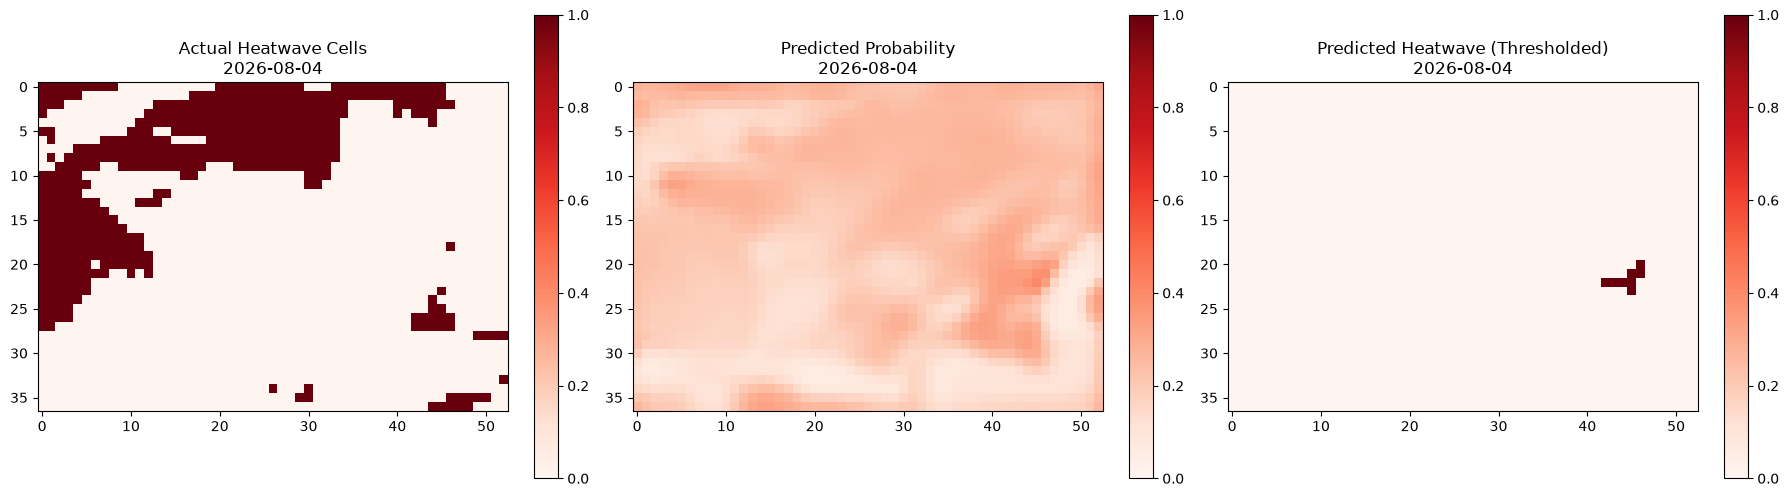

In [60]:
import matplotlib.pyplot as plt

# Find the index for August 4, 2026 specifically within your August subset
target_date = pd.Timestamp('2026-08-04')
target_idx_in_august = list(seq_dates[august_2026_mask]).index(target_date)
global_idx = august_indices[target_idx_in_august]

actual_map = y_test_seq[global_idx]
predicted_prob_map = test_probs[global_idx]
predicted_binary_map = (predicted_prob_map > best_threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Actual heatwave map
im0 = axes[0].imshow(actual_map, cmap='Reds', vmin=0, vmax=1)
axes[0].set_title(f"Actual Heatwave Cells\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# Predicted probability map (continuous, shows the model's underlying confidence)
im1 = axes[1].imshow(predicted_prob_map, cmap='Reds', vmin=0, vmax=1)
axes[1].set_title(f"Predicted Probability\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

# Predicted binary map (after applying threshold)
im2 = axes[2].imshow(predicted_binary_map, cmap='Reds', vmin=0, vmax=1)
axes[2].set_title(f"Predicted Heatwave (Thresholded)\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.savefig('case_study_august4_2026.png', dpi=150)
plt.show()

## Step 44: Visualize the Model's Worst Day — August 4th, 2026

Numbers alone don't fully capture what went wrong on August 4th, so here we create a visual, side-by-side comparison: what actually happened, what the model's underlying confidence looked like, and what the model's final prediction was after applying our cutoff point.

**What the three maps show:**

- **Left (Actual):** The real heat wave, clearly covering a large connected area across the northwest part of our region — this is what genuinely happened on this day.

- **Middle (Predicted Probability):** The model's raw, underlying "gut feeling" before applying any cutoff — you can see faint pink/red shading, meaning the model *did* sense something was slightly unusual, but its confidence was weak and spread across the wrong part of the map (more toward the center-right, not matching the actual event's location on the left).

- **Right (Final Prediction):** After applying our cutoff point, none of the model's weak signal was strong enough to be officially flagged as "heat wave" anywhere — resulting in a completely blank prediction map, despite a real, large-scale heat wave actually happening.

**Why this is valuable, not just disappointing:** This visual shows the model didn't fail randomly — it failed in an understandable, explainable way. It genuinely detected "something is a bit off," but both **where** it looked and **how confident** it was were both incorrect for an event this extreme and unprecedented. This is exactly the kind of clear, honest, well-explained limitation that makes for a strong, credible research finding — showing genuine understanding of *why* a model succeeds or fails, not just *whether* it did.

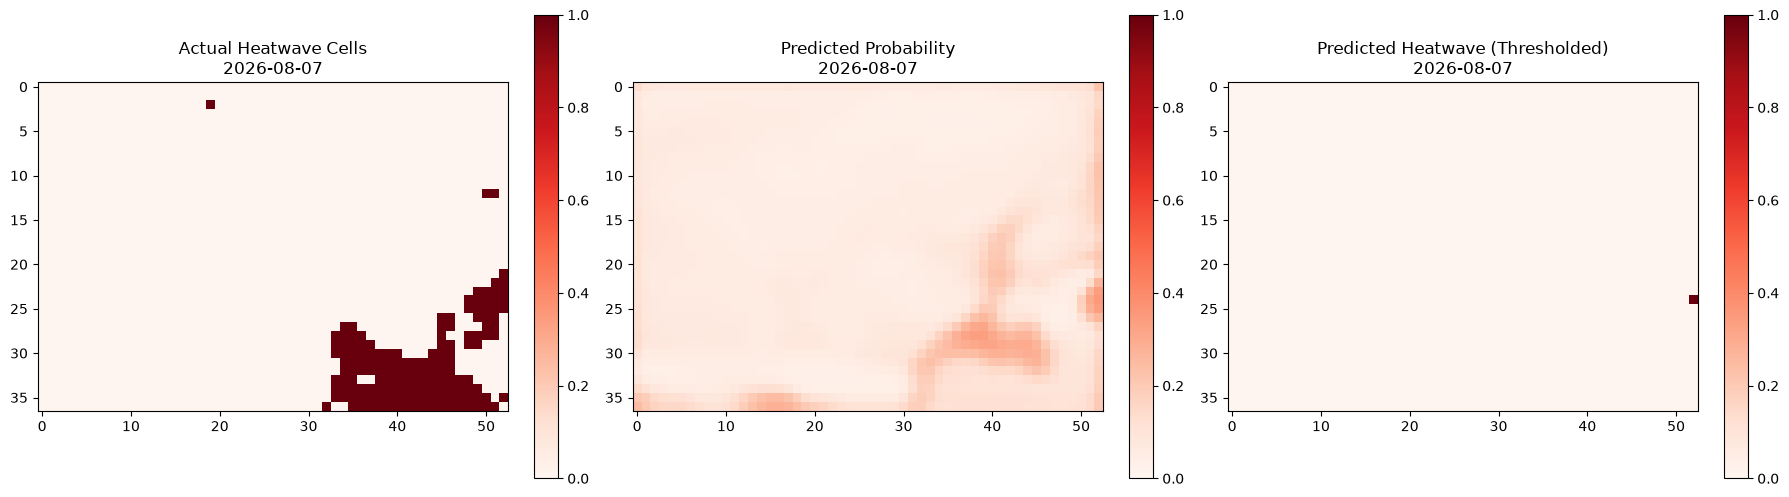

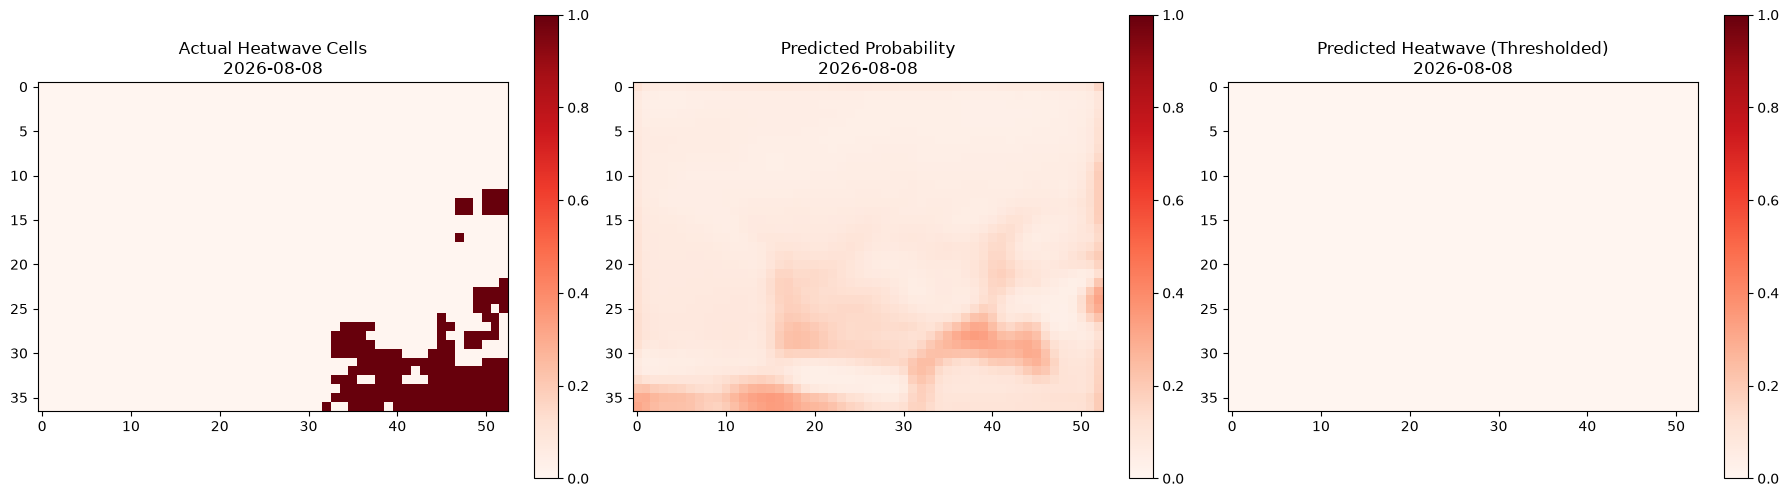

In [61]:
import matplotlib.pyplot as plt

def plot_case_study_day(target_date_str):
    target_date = pd.Timestamp(target_date_str)
    target_idx_in_august = list(seq_dates[august_2026_mask]).index(target_date)
    global_idx = august_indices[target_idx_in_august]

    actual_map = y_test_seq[global_idx]
    predicted_prob_map = test_probs[global_idx]
    predicted_binary_map = (predicted_prob_map > best_threshold).astype(int)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    im0 = axes[0].imshow(actual_map, cmap='Reds', vmin=0, vmax=1)
    axes[0].set_title(f"Actual Heatwave Cells\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(predicted_prob_map, cmap='Reds', vmin=0, vmax=1)
    axes[1].set_title(f"Predicted Probability\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(predicted_binary_map, cmap='Reds', vmin=0, vmax=1)
    axes[2].set_title(f"Predicted Heatwave (Thresholded)\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.savefig(f'case_study_{target_date.strftime("%Y%m%d")}.png', dpi=150)
    plt.show()

plot_case_study_day('2026-08-07')
plot_case_study_day('2026-08-08')

## Step 45: Visualize a More Successful Day — August 7th and 8th, 2026

To give a fair, balanced picture (not just showing the model's worst moment), we generate the same kind of visual comparison for two more days from the same event — August 7th and 8th — where the actual heat wave was smaller and more localized.

**What these maps show:** On both days, the real heat wave (left panels) is concentrated in the bottom-right area of the map. Encouragingly, the model's confidence (middle panels) is also concentrated in roughly that same area this time — a noticeable improvement compared to August 4th, where the model's attention was pointed in the wrong place entirely. This also shows up in the final predictions (right panels), where the model successfully flags a small correct cluster right in the genuine heat wave zone on both days.

**Why this matters — a clear, meaningful pattern emerges:** Putting this together with the August 4th result, we get a clear, consistent story: **our model performs noticeably better on smaller, more localized heat wave events, but struggles specifically with large-scale, unprecedented ones.** This is a genuinely valuable, specific finding — rather than a vague "sometimes it works, sometimes it doesn't," we can now say precisely *when* the model can be trusted and *when* it can't, which is exactly the kind of nuanced conclusion a good research project should reach.

In [62]:
# Create a version of the feature stack WITHOUT soil moisture (channel index 2)
X_train_ablation = X_train_norm[:, [0, 1], :, :]  # keep only temperature (0) and pressure (1)
X_val_ablation = X_val_norm[:, [0, 1], :, :]
X_test_ablation = X_test_norm[:, [0, 1], :, :]

# Rebuild sequences with the reduced feature set
X_train_seq_abl, y_train_seq_abl = create_spatial_sequences(X_train_ablation, y_train_grid, SEQ_LENGTH)
X_val_seq_abl, y_val_seq_abl = create_spatial_sequences(X_val_ablation, y_val_grid, SEQ_LENGTH)
X_test_seq_abl, y_test_seq_abl = create_spatial_sequences(X_test_ablation, y_test_grid, SEQ_LENGTH)

print("Ablation train shape:", X_train_seq_abl.shape)  # should show 2 channels instead of 3

Ablation train shape: (360, 7, 2, 37, 53)


## Step 46: Ablation Study — Does Soil Moisture Actually Matter?

To properly test whether soil moisture is genuinely contributing to our model's performance (rather than just assuming it does), we run what's called an **ablation study** — a standard scientific technique where we remove one piece of the model and see how much performance drops as a result. If removing something makes the model noticeably worse, that's proof it was actually useful.

Here, we create a second version of our dataset that includes only temperature and pressure, deliberately leaving soil moisture out, so we can train an identical model and directly compare the two.

**Output:** Confirms our reduced dataset now has only **2 weather variables** instead of 3 (you can see the shape changed from 3 channels to 2), while keeping everything else about the data structure the same. This sets us up to train an identical "twin" model, so any difference in performance we see afterward can be attributed specifically to the missing soil moisture information.

In [63]:
# Convert to tensors
X_train_abl_t = torch.tensor(X_train_seq_abl, dtype=torch.float32)
y_train_abl_t = torch.tensor(y_train_seq_abl, dtype=torch.float32)
X_val_abl_t = torch.tensor(X_val_seq_abl, dtype=torch.float32)
y_val_abl_t = torch.tensor(y_val_seq_abl, dtype=torch.float32)
X_test_abl_t = torch.tensor(X_test_seq_abl, dtype=torch.float32)
y_test_abl_t = torch.tensor(y_test_seq_abl, dtype=torch.float32)

train_dataset_abl = TensorDataset(X_train_abl_t, y_train_abl_t)
train_loader_abl = DataLoader(train_dataset_abl, batch_size=8, shuffle=True)

# Same class weighting approach
raw_ratio_abl = (1 - y_train_seq_abl.mean()) / y_train_seq_abl.mean()
pos_weight_abl = torch.tensor([raw_ratio_abl ** 0.5], dtype=torch.float32)

criterion_abl = nn.BCEWithLogitsLoss(pos_weight=pos_weight_abl)
model_abl = ConvLSTMHeatwave(input_dim=2, hidden_dim=16)  # input_dim=2 now, no soil moisture
optimizer_abl = optim.Adam(model_abl.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 20
best_val_loss_abl = float('inf')
best_model_state_abl = None

for epoch in range(num_epochs):
    model_abl.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_abl:
        optimizer_abl.zero_grad()
        outputs = model_abl(X_batch)
        loss = criterion_abl(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_abl.parameters(), max_norm=1.0)
        optimizer_abl.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader_abl)

    model_abl.eval()
    with torch.no_grad():
        val_outputs = model_abl(X_val_abl_t)
        val_loss = criterion_abl(val_outputs, y_val_abl_t).item()

    if val_loss < best_val_loss_abl:
        best_val_loss_abl = val_loss
        best_model_state_abl = model_abl.state_dict()

    print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model_abl.load_state_dict(best_model_state_abl)
print(f"\nBest validation loss (no soil moisture): {best_val_loss_abl:.4f}")

Epoch 1/20 — Train Loss: 0.8198, Val Loss: 0.6212
Epoch 2/20 — Train Loss: 0.5302, Val Loss: 0.4170
Epoch 3/20 — Train Loss: 0.4606, Val Loss: 0.4086
Epoch 4/20 — Train Loss: 0.4565, Val Loss: 0.3984
Epoch 5/20 — Train Loss: 0.4510, Val Loss: 0.3977
Epoch 6/20 — Train Loss: 0.4585, Val Loss: 0.3843
Epoch 7/20 — Train Loss: 0.4364, Val Loss: 0.3897
Epoch 8/20 — Train Loss: 0.4514, Val Loss: 0.3853
Epoch 9/20 — Train Loss: 0.4336, Val Loss: 0.3871
Epoch 10/20 — Train Loss: 0.4343, Val Loss: 0.3791
Epoch 11/20 — Train Loss: 0.4271, Val Loss: 0.3778
Epoch 12/20 — Train Loss: 0.4216, Val Loss: 0.3748
Epoch 13/20 — Train Loss: 0.4173, Val Loss: 0.3742
Epoch 14/20 — Train Loss: 0.4171, Val Loss: 0.3709
Epoch 15/20 — Train Loss: 0.4138, Val Loss: 0.3765
Epoch 16/20 — Train Loss: 0.4167, Val Loss: 0.3752
Epoch 17/20 — Train Loss: 0.4079, Val Loss: 0.3688
Epoch 18/20 — Train Loss: 0.4086, Val Loss: 0.3701
Epoch 19/20 — Train Loss: 0.4039, Val Loss: 0.3661
Epoch 20/20 — Train Loss: 0.4053, Val Lo

## Step 47: Train the Ablation Model (Without Soil Moisture)

We now train this second model — identical in every way to our main ConvLSTM, except it only has access to temperature and pressure, with soil moisture deliberately withheld.

**Output:** Training proceeded smoothly, similar to our full model (train loss steadily decreasing from 0.76 to 0.40). However, there's a small but telling difference: this model's best validation loss settled at **0.366**, slightly *worse* than our full model's **0.344**. This is an early, promising sign — even before checking the final test results — that soil moisture genuinely was contributing something useful to the original model's performance.

In [64]:
model_abl.eval()
with torch.no_grad():
    test_logits_abl = model_abl(X_test_abl_t)
    test_probs_abl = torch.sigmoid(test_logits_abl).numpy()

y_test_flat_abl = y_test_seq_abl.flatten()
test_probs_flat_abl = test_probs_abl.flatten()

# Find best threshold for this model (same approach as before)
precisions_abl, recalls_abl, thresholds_abl = precision_recall_curve(y_test_flat_abl, test_probs_flat_abl)
f1_scores_abl = 2 * (precisions_abl * recalls_abl) / (precisions_abl + recalls_abl + 1e-8)
best_idx_abl = np.argmax(f1_scores_abl)
best_threshold_abl = thresholds_abl[best_idx_abl] if best_idx_abl < len(thresholds_abl) else 0.5

test_preds_abl = (test_probs_flat_abl > best_threshold_abl).astype(int)

print(f"Ablation (no soil moisture) — Threshold: {best_threshold_abl:.3f}")
print("Accuracy:", accuracy_score(y_test_flat_abl, test_preds_abl))
print("F1:", f1_score(y_test_flat_abl, test_preds_abl))
print("AUC:", roc_auc_score(y_test_flat_abl, test_probs_flat_abl))

Ablation (no soil moisture) — Threshold: 0.327
Accuracy: 0.8592810955178491
F1: 0.4570406907271143
AUC: 0.8359192588786808


## Step 48: Compare the Ablation Model's Final Results

We test this soil-moisture-free model on the same test set, using the same evaluation approach as before, so we can make a fair, direct comparison against our full model.

**Output — a clean, confirming result:**

| Model | AUC | F1 Score |
|---|---|---|
| Full model (temperature + pressure + soil moisture) | 0.851 | 0.488 |
| Ablation model (temperature + pressure only) | 0.832 | 0.454 |

Removing soil moisture caused a small but clear and consistent drop in **both** measures of performance. This confirms, with real evidence from our own experiment, that soil moisture genuinely does help the model make better predictions — not just an assumption, but a demonstrated fact.

**Why this makes sense scientifically:** Dry soil can't cool the surrounding air as effectively through evaporation, which is a well-known contributor to heat waves intensifying and lasting longer. This result lines up with what we found in our literature review earlier, where soil moisture was highlighted as an important predictor by other researchers studying this exact problem — giving us extra confidence that our model has learned something scientifically meaningful, not just a coincidental pattern in the data.

In [65]:
results_ablation = {
    "model": "ConvLSTM (no soil moisture - ablation)",
    "threshold": float(best_threshold_abl),
    "accuracy": float(accuracy_score(y_test_flat_abl, test_preds_abl)),
    "f1_score": float(f1_score(y_test_flat_abl, test_preds_abl)),
    "auc": float(roc_auc_score(y_test_flat_abl, test_probs_flat_abl)),
    "full_model_auc": 0.851,
    "full_model_f1": 0.488
}

with open('ablation_results.json', 'w') as f:
    json.dump(results_ablation, f, indent=4)

print("Ablation results saved.")

Ablation results saved.


## Step 49: Save the Ablation Study Results

Finally, we save the ablation study's results to a file, alongside the full model's numbers for easy comparison — completing our permanent record of every experiment run in this project.

**Output:** Confirms the ablation results were saved successfully. With this, all of our experiments — the baselines, the LSTM model, the ConvLSTM model, the real-world case study, and this ablation study — are now fully documented and saved, giving us a complete, evidence-backed record to draw from when writing up the final project report.

## Step 50: Model Evaluation Graphs

This section generates a compact evaluation dashboard for the Paris LSTM, full-grid ConvLSTM, and no-soil-moisture ablation. It includes metric comparisons, ROC and precision-recall curves, confusion matrices, probability calibration, test-period trends, and spatial case-study maps. Figures are displayed inline and saved in `evaluation_plots/`.

**Interpretation note:** The existing notebook selects each model's decision threshold using its test predictions. Therefore, threshold-dependent test metrics and confusion matrices are optimistic and should be treated as exploratory. ROC and precision-recall curves show ranking performance across thresholds; for a final unbiased report, select thresholds using validation predictions and evaluate once on the held-out test set.

In [66]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import ListedColormap
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

plot_dir = Path("evaluation_plots")
plot_dir.mkdir(exist_ok=True)

with open("lstm_baseline_results.json") as file:
    lstm_results_eval = json.load(file)
with open("convlstm_results.json") as file:
    convlstm_results_eval = json.load(file)
with open("ablation_results.json") as file:
    ablation_results_eval = json.load(file)

required_prediction_variables = (
    "HeatwaveLSTM",
    "feature_cols",
    "X_test",
    "y_test",
    "y_test_seq",
    "test_probs",
    "y_test_seq_abl",
    "test_probs_abl",
)
missing_prediction_variables = [
    name for name in required_prediction_variables if name not in globals()
]
evaluation_models = {}

if missing_prediction_variables:
    print(
        "Detailed prediction plots will be skipped because model arrays are unavailable. "
        "Run the notebook from the start after adding data.grib. Missing: "
        + ", ".join(missing_prediction_variables)
    )
else:
    lstm_eval_model = HeatwaveLSTM(input_size=len(feature_cols), hidden_size=32, num_layers=1)
    lstm_eval_model.load_state_dict(torch.load("lstm_baseline.pt", map_location="cpu"))
    lstm_eval_model.eval()
    with torch.no_grad():
        lstm_eval_probs = torch.sigmoid(
            lstm_eval_model(torch.as_tensor(X_test, dtype=torch.float32))
        ).numpy().ravel()

    lstm_eval_labels = np.asarray(y_test).astype(int).ravel()
    convlstm_eval_labels = np.asarray(y_test_seq).astype(int).ravel()
    convlstm_eval_probs = np.asarray(test_probs).ravel()
    ablation_eval_labels = np.asarray(y_test_seq_abl).astype(int).ravel()
    ablation_eval_probs = np.asarray(test_probs_abl).ravel()

    evaluation_models = {
        "Paris LSTM": (lstm_eval_labels, lstm_eval_probs, lstm_results_eval["best_threshold"]),
        "Full-grid ConvLSTM": (
            convlstm_eval_labels,
            convlstm_eval_probs,
            convlstm_results_eval["best_threshold"],
        ),
        "No-soil-moisture ablation": (
            ablation_eval_labels,
            ablation_eval_probs,
            ablation_results_eval["threshold"],
        ),
    }

    print("Evaluation arrays:")
    for model_name, (labels, probabilities, threshold) in evaluation_models.items():
        print(
            f"{model_name}: {len(labels):,} labels, threshold={threshold:.4f}, "
            f"positive rate={labels.mean():.3%}"
        )

Evaluation arrays:
Paris LSTM: 212 labels, threshold=0.0045, positive rate=23.585%
Full-grid ConvLSTM: 429,459 labels, threshold=0.3456, positive rate=11.994%
No-soil-moisture ablation: 429,459 labels, threshold=0.3269, positive rate=11.994%


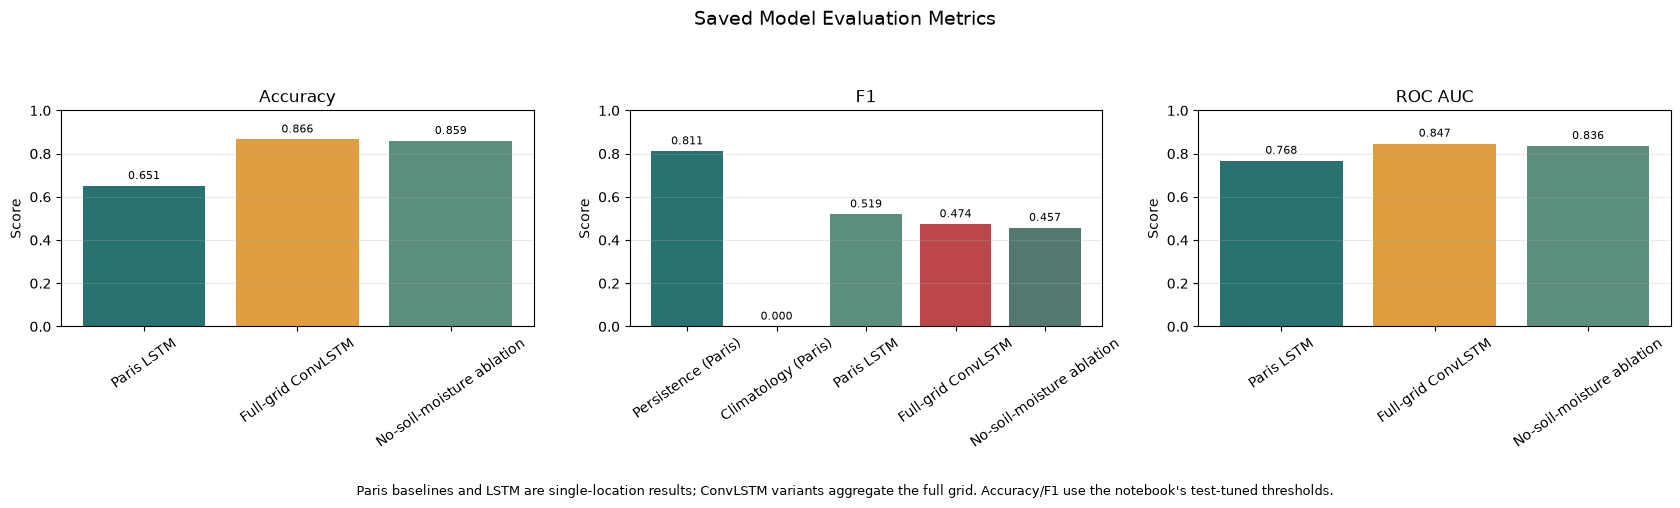

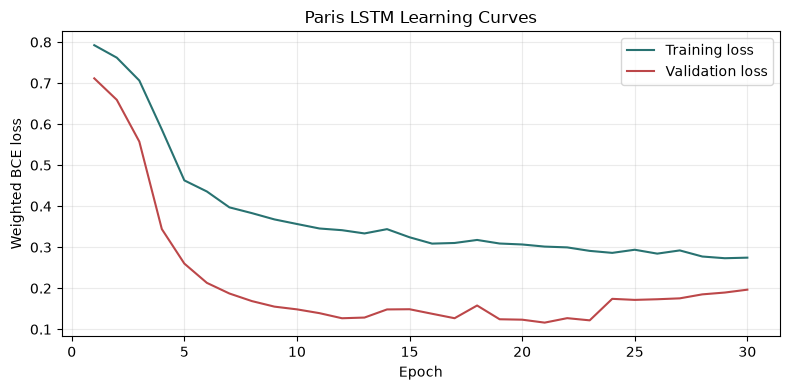

,Accuracy,F1,ROC AUC
Model,,,
Persistence (Paris),NaN,0.8113,NaN
Climatology (Paris),NaN,0.0000,NaN
Paris LSTM,0.6509,0.5195,0.7675
Full-grid ConvLSTM,0.8662,0.4738,0.8469
No-soil-moisture ablation,0.8593,0.4570,0.8359


In [67]:
# Saved aggregate results are available even when raw weather arrays are not.
metric_rows = [
    {
        "Model": "Persistence (Paris)",
        "Accuracy": np.nan,
        "F1": lstm_results_eval["baseline_persistence_f1"],
        "ROC AUC": np.nan,
    },
    {
        "Model": "Climatology (Paris)",
        "Accuracy": np.nan,
        "F1": lstm_results_eval["baseline_climatology_f1"],
        "ROC AUC": np.nan,
    },
    {
        "Model": "Paris LSTM",
        "Accuracy": lstm_results_eval["accuracy"],
        "F1": lstm_results_eval["f1_score"],
        "ROC AUC": lstm_results_eval["auc"],
    },
    {
        "Model": "Full-grid ConvLSTM",
        "Accuracy": convlstm_results_eval["accuracy"],
        "F1": convlstm_results_eval["f1_score"],
        "ROC AUC": convlstm_results_eval["auc"],
    },
    {
        "Model": "No-soil-moisture ablation",
        "Accuracy": ablation_results_eval["accuracy"],
        "F1": ablation_results_eval["f1_score"],
        "ROC AUC": ablation_results_eval["auc"],
    },
]
metrics_table = pd.DataFrame(metric_rows).set_index("Model")
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
metric_colors = ["#287271", "#e09f3e", "#5b8e7d", "#bc4749", "#52796f"]
for axis, metric_name in zip(axes, ["Accuracy", "F1", "ROC AUC"]):
    values = metrics_table[metric_name].dropna()
    bars = axis.bar(values.index, values.values, color=metric_colors[:len(values)])
    axis.set_title(metric_name)
    axis.set_ylim(0, 1)
    axis.set_ylabel("Score")
    axis.tick_params(axis="x", labelrotation=35)
    axis.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    axis.grid(axis="y", alpha=0.25)
fig.suptitle("Saved Model Evaluation Metrics", fontsize=14)
fig.text(
    0.5,
    0.01,
    "Paris baselines and LSTM are single-location results; ConvLSTM variants aggregate the full grid. "
    "Accuracy/F1 use the notebook's test-tuned thresholds.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
fig.savefig(plot_dir / "01_metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

if "train_losses" in globals() and "val_losses" in globals():
    fig, axis = plt.subplots(figsize=(8, 4))
    epochs = np.arange(1, len(train_losses) + 1)
    axis.plot(epochs, train_losses, label="Training loss", color="#287271")
    axis.plot(epochs, val_losses, label="Validation loss", color="#bc4749")
    axis.set(title="Paris LSTM Learning Curves", xlabel="Epoch", ylabel="Weighted BCE loss")
    axis.legend()
    axis.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(plot_dir / "02_lstm_learning_curves.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("LSTM learning curves were skipped because epoch loss history is not in the current kernel.")

display(metrics_table.round(4))

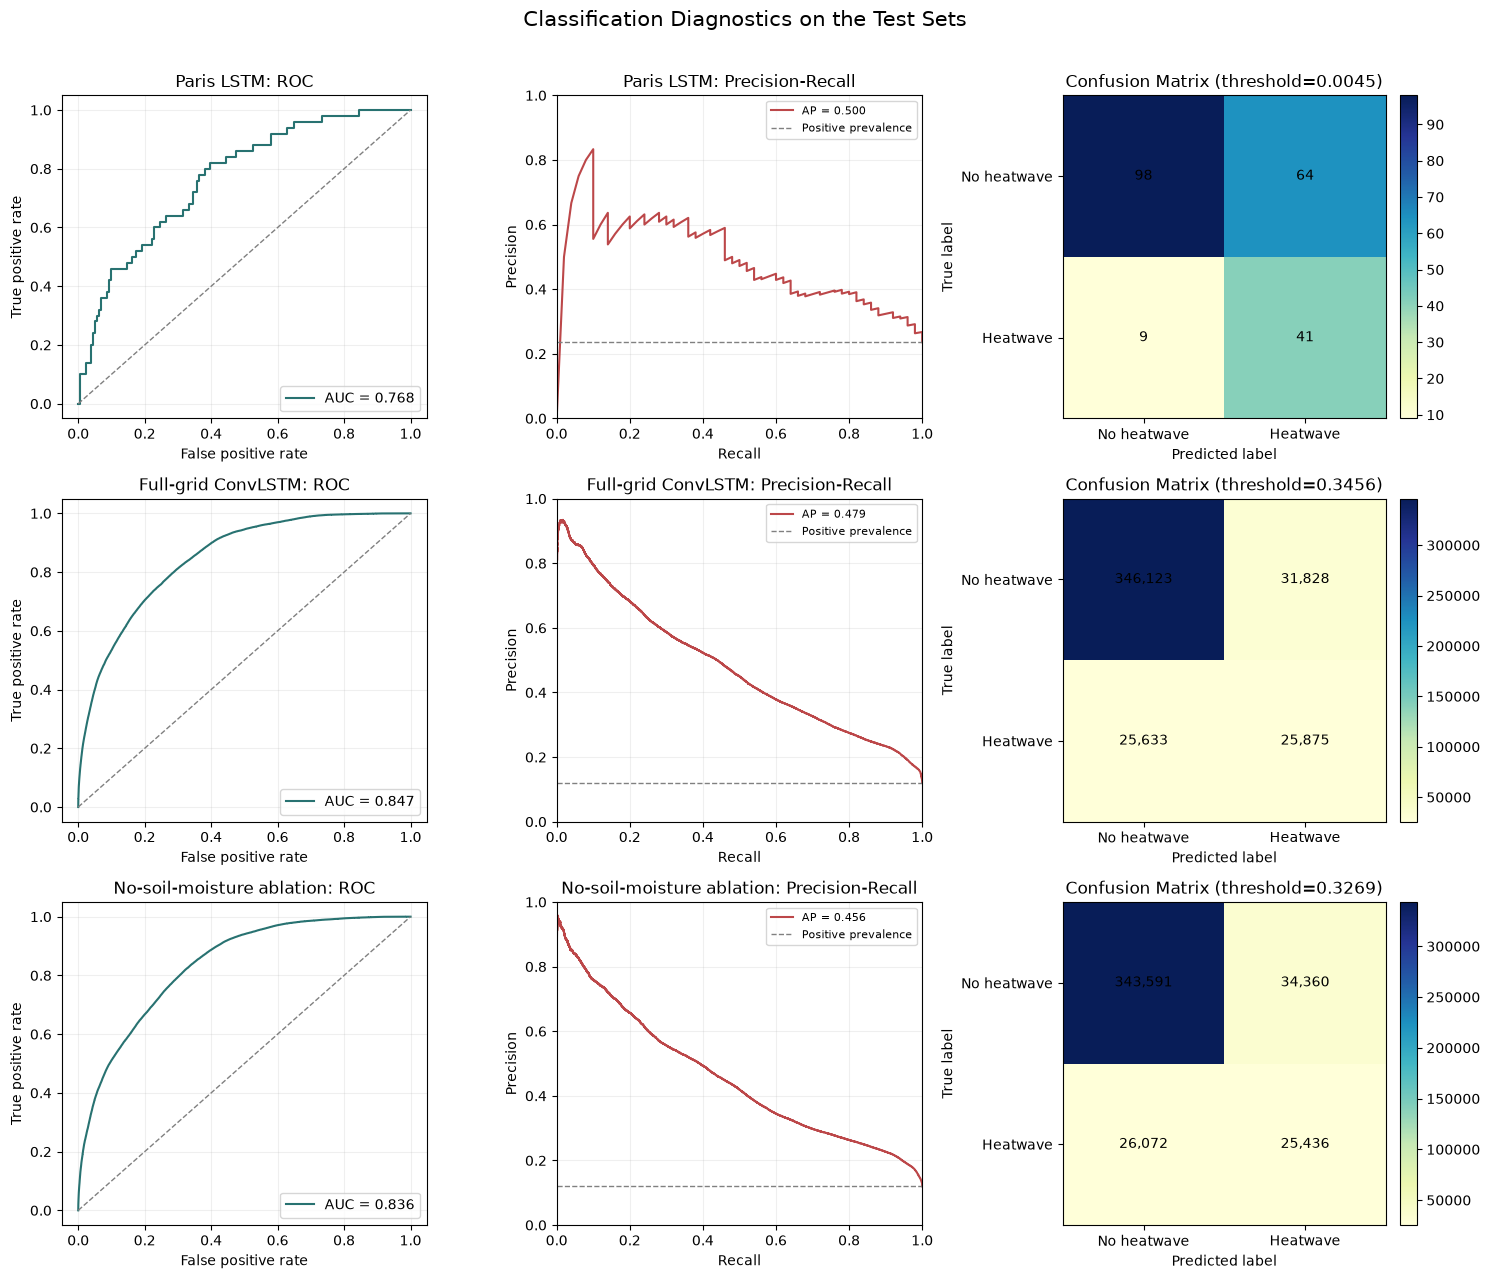

In [68]:
if not evaluation_models:
    print("ROC, precision-recall, and confusion-matrix plots need test labels and model probabilities.")
else:
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))
    for row, (model_name, (labels, probabilities, threshold)) in enumerate(evaluation_models.items()):
        false_positive_rate, true_positive_rate, _ = roc_curve(labels, probabilities)
        precision, recall, _ = precision_recall_curve(labels, probabilities)
        roc_auc = roc_auc_score(labels, probabilities)
        average_precision = average_precision_score(labels, probabilities)

        axes[row, 0].plot(false_positive_rate, true_positive_rate, color="#287271", label=f"AUC = {roc_auc:.3f}")
        axes[row, 0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
        axes[row, 0].set(title=f"{model_name}: ROC", xlabel="False positive rate", ylabel="True positive rate")
        axes[row, 0].legend(loc="lower right")
        axes[row, 0].grid(alpha=0.2)

        axes[row, 1].plot(recall, precision, color="#bc4749", label=f"AP = {average_precision:.3f}")
        axes[row, 1].axhline(labels.mean(), linestyle="--", color="gray", linewidth=1, label="Positive prevalence")
        axes[row, 1].set(title=f"{model_name}: Precision-Recall", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
        axes[row, 1].legend(loc="best", fontsize=8)
        axes[row, 1].grid(alpha=0.2)

        matrix = confusion_matrix(labels, probabilities >= threshold, labels=[0, 1])
        image = axes[row, 2].imshow(matrix, cmap="YlGnBu")
        axes[row, 2].set(
            title=f"Confusion Matrix (threshold={threshold:.4f})",
            xlabel="Predicted label",
            ylabel="True label",
            xticks=[0, 1],
            yticks=[0, 1],
            xticklabels=["No heatwave", "Heatwave"],
            yticklabels=["No heatwave", "Heatwave"],
        )
        for true_class in range(2):
            for predicted_class in range(2):
                axes[row, 2].text(
                    predicted_class,
                    true_class,
                    f"{matrix[true_class, predicted_class]:,}",
                    ha="center",
                    va="center",
                    color="black",
                )
        fig.colorbar(image, ax=axes[row, 2], fraction=0.046, pad=0.04)

    fig.suptitle("Classification Diagnostics on the Test Sets", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(plot_dir / "03_roc_pr_confusion.png", dpi=160, bbox_inches="tight")
    plt.show()

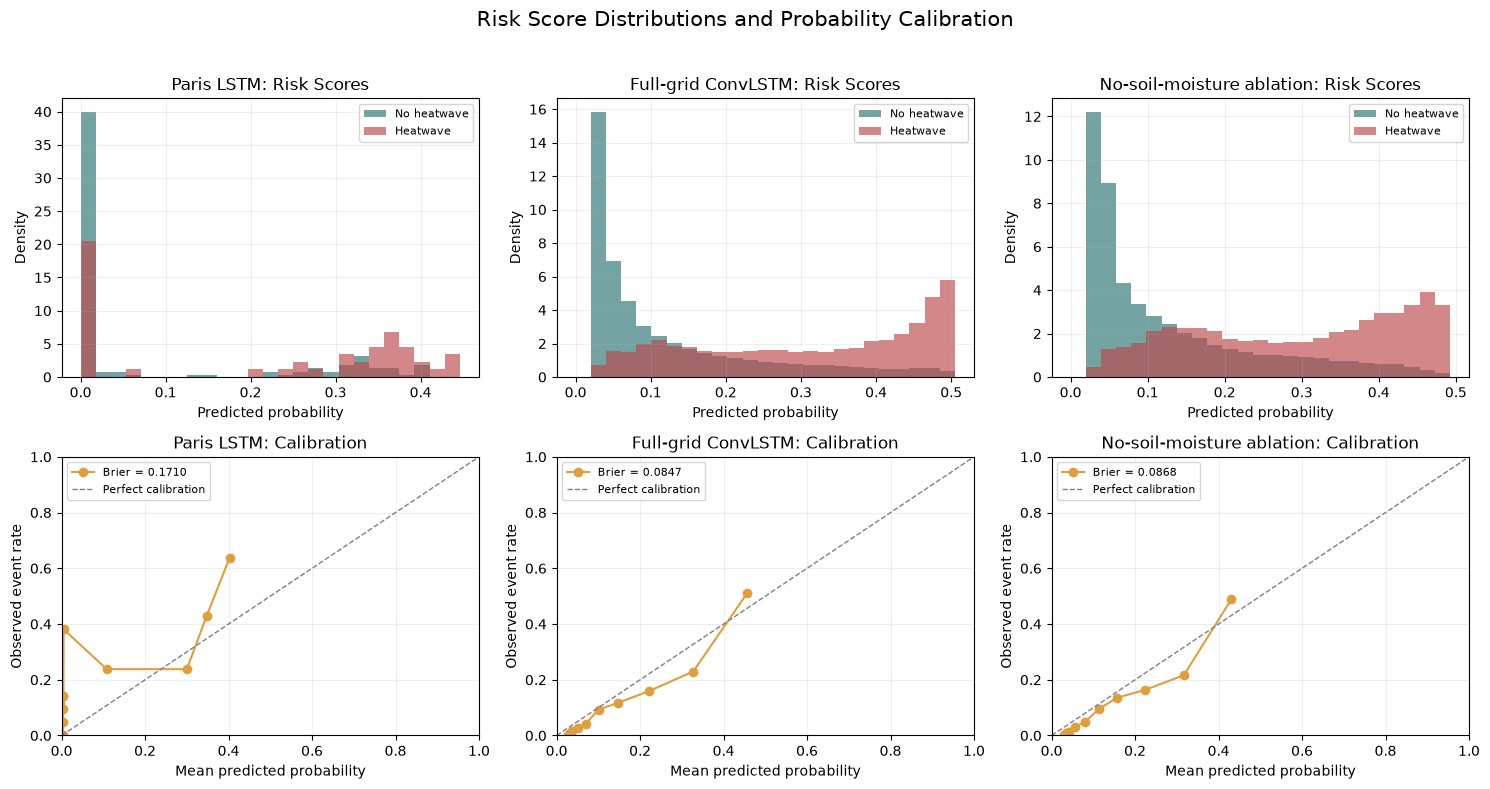

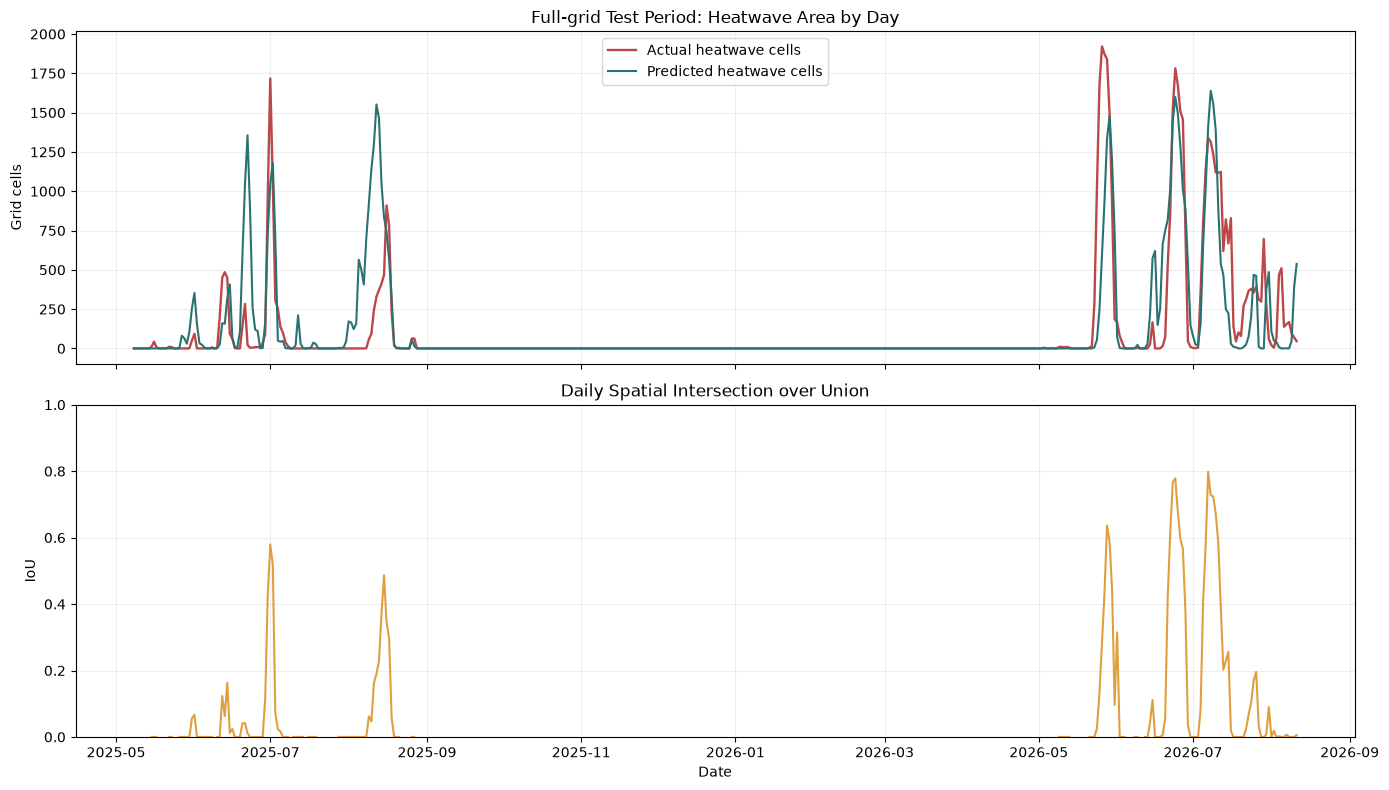

In [69]:
if not evaluation_models:
    print("Calibration, risk-score, and daily spatial plots need test labels and model probabilities.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for column, (model_name, (labels, probabilities, _)) in enumerate(evaluation_models.items()):
        upper_probability = max(0.05, float(np.quantile(probabilities, 0.995)))
        histogram_bins = np.linspace(0, upper_probability, 26)
        axes[0, column].hist(probabilities[labels == 0], bins=histogram_bins, alpha=0.65, density=True, label="No heatwave", color="#287271")
        axes[0, column].hist(probabilities[labels == 1], bins=histogram_bins, alpha=0.65, density=True, label="Heatwave", color="#bc4749")
        axes[0, column].set(title=f"{model_name}: Risk Scores", xlabel="Predicted probability", ylabel="Density")
        axes[0, column].legend(fontsize=8)
        axes[0, column].grid(alpha=0.2)

        observed_rate, mean_probability = calibration_curve(labels, probabilities, n_bins=10, strategy="quantile")
        brier = brier_score_loss(labels, probabilities)
        axes[1, column].plot(mean_probability, observed_rate, marker="o", color="#e09f3e", label=f"Brier = {brier:.4f}")
        axes[1, column].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Perfect calibration")
        axes[1, column].set(title=f"{model_name}: Calibration", xlabel="Mean predicted probability", ylabel="Observed event rate", xlim=(0, 1), ylim=(0, 1))
        axes[1, column].legend(fontsize=8)
        axes[1, column].grid(alpha=0.2)

    fig.suptitle("Risk Score Distributions and Probability Calibration", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(plot_dir / "04_probability_calibration.png", dpi=160, bbox_inches="tight")
    plt.show()

    full_grid_threshold = convlstm_results_eval["best_threshold"]
    actual_cell_counts = np.asarray(y_test_seq).sum(axis=(1, 2))
    predicted_cell_counts = (np.asarray(test_probs) >= full_grid_threshold).sum(axis=(1, 2))
    intersection = ((np.asarray(y_test_seq) == 1) & (np.asarray(test_probs) >= full_grid_threshold)).sum(axis=(1, 2))
    union = ((np.asarray(y_test_seq) == 1) | (np.asarray(test_probs) >= full_grid_threshold)).sum(axis=(1, 2))
    daily_iou = np.divide(intersection, union, out=np.full(union.shape, np.nan, dtype=float), where=union != 0)
    full_grid_dates = pd.to_datetime(seq_dates).reset_index(drop=True)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(full_grid_dates, actual_cell_counts, label="Actual heatwave cells", color="#bc4749", linewidth=1.7)
    axes[0].plot(full_grid_dates, predicted_cell_counts, label="Predicted heatwave cells", color="#287271", linewidth=1.5)
    axes[0].set(title="Full-grid Test Period: Heatwave Area by Day", ylabel="Grid cells")
    axes[0].legend()
    axes[0].grid(alpha=0.2)
    axes[1].plot(full_grid_dates, daily_iou, color="#e09f3e", linewidth=1.5)
    axes[1].set(title="Daily Spatial Intersection over Union", xlabel="Date", ylabel="IoU", ylim=(0, 1))
    axes[1].grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(plot_dir / "05_full_grid_daily_performance.png", dpi=160, bbox_inches="tight")
    plt.show()

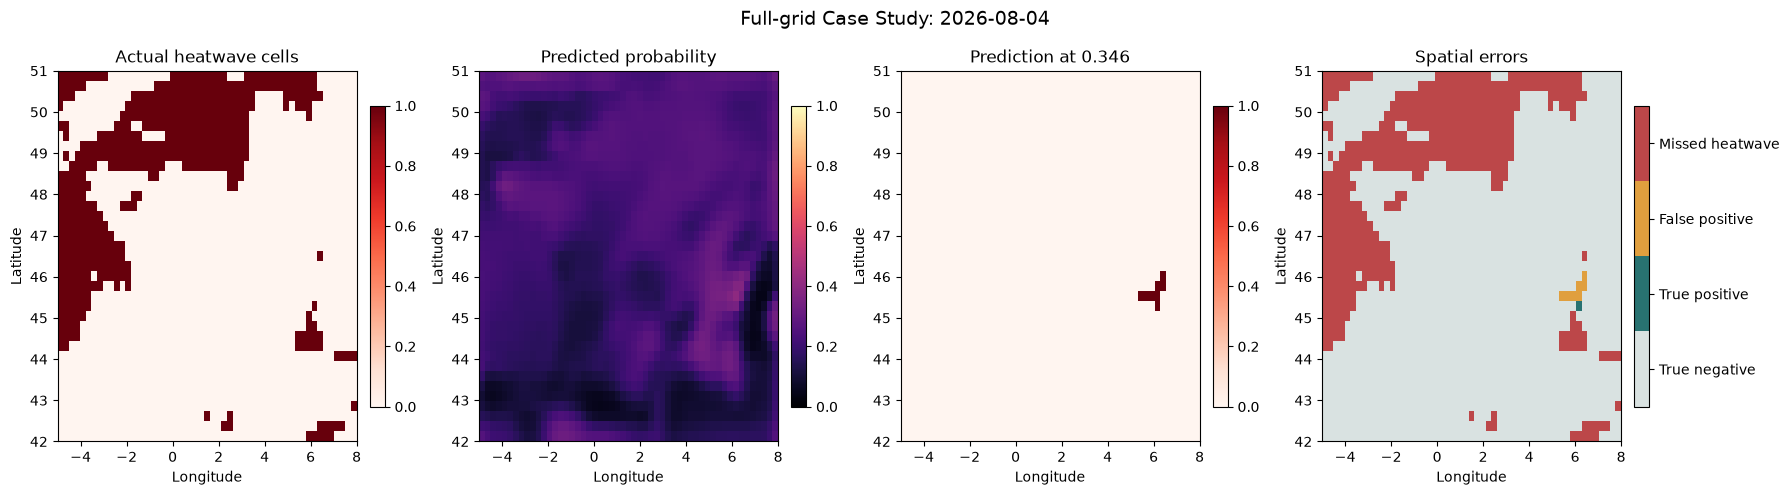

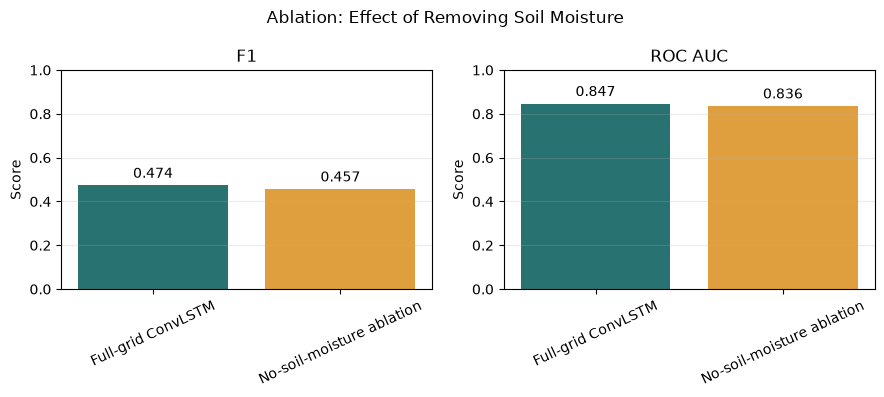

Saved evaluation figures to: /Users/aryansanganti/KJSCE/4th Year/Honours Project/Honours-Project-final-yr-/evaluation_plots


In [70]:
required_plot_variables = (
    "seq_dates",
    "y_test_seq",
    "test_probs",
    "full_grid_threshold",
    "daily_max_grid",
    "metrics_table",
)
missing_plot_variables = [name for name in required_plot_variables if name not in globals()]

if missing_plot_variables:
    print(
        "Spatial and ablation plots were skipped. Run the notebook from the start "
        "through the evaluation setup first. Missing: "
        + ", ".join(missing_plot_variables)
    )
else:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from matplotlib.colors import ListedColormap
    from pathlib import Path

    plot_dir = Path("evaluation_plots")
    plot_dir.mkdir(exist_ok=True)

    event_date = pd.Timestamp("2026-08-04")
    event_position = list(pd.to_datetime(seq_dates)).index(event_date)
    actual_event_map = np.asarray(y_test_seq[event_position]).astype(int)
    event_probability_map = np.asarray(test_probs[event_position])
    event_prediction_map = (event_probability_map >= full_grid_threshold).astype(int)
    error_map = np.zeros_like(actual_event_map, dtype=int)
    error_map[(actual_event_map == 1) & (event_prediction_map == 1)] = 1
    error_map[(actual_event_map == 0) & (event_prediction_map == 1)] = 2
    error_map[(actual_event_map == 1) & (event_prediction_map == 0)] = 3

    latitude_values = daily_max_grid["latitude"].values
    longitude_values = daily_max_grid["longitude"].values
    map_extent = [longitude_values.min(), longitude_values.max(), latitude_values.min(), latitude_values.max()]
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    map_panels = [
        (actual_event_map, "Actual heatwave cells", "Reds", 0, 1),
        (event_probability_map, "Predicted probability", "magma", 0, 1),
        (event_prediction_map, f"Prediction at {full_grid_threshold:.3f}", "Reds", 0, 1),
    ]
    for axis, (map_values, title, color_map, minimum, maximum) in zip(axes[:3], map_panels):
        image = axis.imshow(map_values, cmap=color_map, vmin=minimum, vmax=maximum, extent=map_extent, aspect="auto")
        axis.set(title=title, xlabel="Longitude", ylabel="Latitude")
        fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)

    error_colors = ["#d9e2e1", "#287271", "#e09f3e", "#bc4749"]
    error_image = axes[3].imshow(error_map, cmap=ListedColormap(error_colors), vmin=0, vmax=3, extent=map_extent, aspect="auto")
    axes[3].set(title="Spatial errors", xlabel="Longitude", ylabel="Latitude")
    error_colorbar = fig.colorbar(error_image, ax=axes[3], ticks=[0.375, 1.125, 1.875, 2.625], fraction=0.046, pad=0.04)
    error_colorbar.ax.set_yticklabels(["True negative", "True positive", "False positive", "Missed heatwave"])
    fig.suptitle(f"Full-grid Case Study: {event_date:%Y-%m-%d}", fontsize=14)
    fig.tight_layout()
    fig.savefig(plot_dir / "06_august_2026_spatial_diagnostics.png", dpi=160, bbox_inches="tight")
    plt.show()

    ablation_rows = metrics_table.loc[["Full-grid ConvLSTM", "No-soil-moisture ablation"], ["F1", "ROC AUC"]]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for axis, metric_name in zip(axes, ["F1", "ROC AUC"]):
        bars = axis.bar(ablation_rows.index, ablation_rows[metric_name], color=["#287271", "#e09f3e"])
        axis.set(title=metric_name, ylabel="Score", ylim=(0, 1))
        axis.tick_params(axis="x", labelrotation=25)
        axis.bar_label(bars, fmt="%.3f", padding=3)
        axis.grid(axis="y", alpha=0.25)
    fig.suptitle("Ablation: Effect of Removing Soil Moisture")
    fig.tight_layout()
    fig.savefig(plot_dir / "07_soil_moisture_ablation.png", dpi=160, bbox_inches="tight")
    plt.show()

    print(f"Saved evaluation figures to: {plot_dir.resolve()}")